# Task 2, step 2: image baselines (OASIS-1, subjects aged 60+)

Trains image models on the 2D slices produced by `data-preparation-for-baselines.ipynb` and evaluates them on the **same subject-wise 5 folds** used by the tabular baselines.

**Models, in three groups** (all from `timm` with ImageNet weights, except RepLKNet)
- **Classic CNNs:** EfficientNet-B0, ResNet50, DenseNet201, MobileNetV2
- **Modern CNNs:** ConvNeXt (tiny), ConvNeXt V2 (tiny), NFNet (L0), InceptionNeXt (tiny), RepLKNet, EfficientNetV2 (RW-S)
- **Transformers:** ViT-B/16, Swin (tiny), DeiT (base), BEiT (base), MaxViT (tiny), CAFormer (S18)

**RepLKNet is the exception:** `timm` has no RepLKNet, so a compact version is built in section 2b and trained from scratch. DeiT-base has the same architecture as ViT-B/16, so that pair shows the effect of the pretraining recipe alone.

**Protocol (identical for every model, so the comparison is fair)**
1. Outer loop: the 5 folds in `subjects_folds.csv`. Each fold is the test set once.
2. Inside the 4 training folds, about 15% of the **subjects** (stratified on the 3-class label) are held out as a validation set. It is used only to pick the best epoch (lowest validation loss). The test fold is never used for any choice.
3. Training is on individual slices. Prediction is on **subjects**: the class probabilities of a subject's 17 slices are averaged, and every metric is computed on those 198 subject-level predictions.
4. One fixed set of hyperparameters per model, not tuned on the test folds.
5. Out-of-fold subject predictions are saved so later models (the GCN) can be compared with a paired test on the same subjects.

**Before you run:** switch **Internet on** in the Kaggle notebook settings (`timm` downloads the pretrained weights), and use a GPU. Set `SMOKE_TEST = True` first to check the whole pipeline in a few minutes.

**Run time:** 16 models x 5 folds takes far longer than the original 5 models. Use `RUN_GROUPS` in the settings cell to run one group per Kaggle session. Each session saves its own results, and `eval-from-preds.ipynb` combines them. If a model runs out of GPU memory (the base-size transformers and MaxViT are the heaviest), lower `BATCH`.

In [1]:
import os, json, time, copy, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import (roc_auc_score, balanced_accuracy_score, accuracy_score,
                             f1_score, confusion_matrix, roc_curve)
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# ----------------------------- EDIT THESE -----------------------------
DATA_DIR   = Path("/kaggle/input/notebooks/stillniloy/data-preparation-for-baselines")   # output of the data-preparation notebook
TASK       = "binary"          # "binary" (CDR 0 vs >0) or "three_class" (CDR 0 / 0.5 / 1+)
SMOKE_TEST = False             # True: fold 0 only, 2 epochs, results go to a separate folder
PRETRAINED = True              # ImageNet weights (needs internet in Kaggle)

# name -> (timm model name, learning rate). One fixed setting per model.
CLASSIC_CNNS = {
    "EfficientNet-B0": ("efficientnet_b0",                3e-4),
    "ResNet50":        ("resnet50",                       1e-4),
    "DenseNet201":     ("densenet201",                    1e-4),
    "MobileNetV2":     ("mobilenetv2_100",                3e-4),
}
MODERN_CNNS = {
    "ConvNeXt":        ("convnext_tiny",                  1e-4),
    "ConvNeXt V2":     ("convnextv2_tiny",                1e-4),
    "NFNet":           ("nfnet_l0",                       1e-4),
    "InceptionNeXt":   ("inception_next_tiny",            1e-4),
    "RepLKNet":        ("replknet",                       1e-3),   # not in timm: compact version trained from scratch (section 2b)
    "EfficientNetV2":  ("efficientnetv2_rw_s",            3e-4),
}
TRANSFORMERS = {
    "ViT-B/16":        ("vit_base_patch16_224",           5e-5),
    "Swin":            ("swin_tiny_patch4_window7_224",   5e-5),
    "DeiT":            ("deit_base_patch16_224",          5e-5),   # same architecture as ViT-B/16, different pretraining
    "BEiT":            ("beit_base_patch16_224",          5e-5),
    "MaxViT":          ("maxvit_tiny_tf_224",             1e-4),
    "CAFormer":        ("caformer_s18",                   1e-4),
}
GROUPS = {"Classic CNNs": CLASSIC_CNNS, "Modern CNNs": MODERN_CNNS, "Transformers": TRANSFORMERS}
RUN_GROUPS = ["Classic CNNs", "Modern CNNs", "Transformers"]     # remove a group here to run it in another session
GROUP_COLORS = {"Classic CNNs": "C0", "Modern CNNs": "C1", "Transformers": "C2"}

# compact RepLKNet (section 2b): channels, blocks per stage, large kernel per stage, small parallel kernel
REPLK = dict(channels=(64, 128, 256, 512), layers=(2, 2, 6, 2), kernels=(31, 29, 27, 13), small_k=5, drop_path=0.1)
IMG_SIZE    = 224
BATCH       = 64
EPOCHS      = 15
PATIENCE    = 5        # early stopping on validation loss
WEIGHT_DECAY = 1e-2
DROP_RATE   = 0.2
VAL_FRAC    = 0.15     # share of training subjects used for validation
SEED        = 42
SAVE_EMBEDDINGS = True         # save each test fold's embeddings for the UMAP in section 6e (False skips this)
NUM_WORKERS = 2
# ----------------------------------------------------------------------

if SMOKE_TEST:
    EPOCHS, FOLDS = 2, [0]
    OUT_DIR = Path("/kaggle/working/baselines_smoke")
else:
    FOLDS = [0, 1, 2, 3, 4]
    OUT_DIR = Path("/kaggle/working/baselines")
OUT_DIR.mkdir(parents=True, exist_ok=True)

MODELS   = {n: spec for g in RUN_GROUPS for n, spec in GROUPS[g].items()}
GROUP_OF = {n: g for g, d in GROUPS.items() for n in d}

def by_group(models):
    # [(group, [models in that group])] in group order, skipping empty groups
    return [(g, [m for m in models if GROUP_OF.get(m) == g]) for g in GROUPS if any(GROUP_OF.get(m) == g for m in models)]

def panel_axes(n, per_row=3, w=4.8, h=4.4):
    ncol = min(per_row, n); nrow = -(-n // ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(w * ncol, h * nrow), squeeze=False)
    axes = axes.ravel()
    for ax in axes[n:]: ax.axis("off")
    return fig, axes[:n]

device  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("device:", device, "| torch", torch.__version__, "| timm", timm.__version__)
if device.type == "cpu":
    print("WARNING: no GPU found. This will be very slow.")

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)

device: cuda | torch 2.11.0+cu128 | timm 1.0.29


## 1. Load the prepared data

In [2]:
if not (DATA_DIR / "prep_config.json").exists():          # find the prepared data if the path above is wrong
    hits = sorted(Path("/kaggle/input").rglob("prep_config.json"))
    print("found:", hits)
    assert hits, "prep_config.json not found: attach the prepared dataset or set DATA_DIR"
    DATA_DIR = hits[0].parent
cfg  = json.load(open(DATA_DIR / "/kaggle/input/notebooks/stillniloy/data-preparation-for-baselines/oasis1_60plus/prep_config.json"))
X    = np.load(DATA_DIR / "/kaggle/input/notebooks/stillniloy/data-preparation-for-baselines/oasis1_60plus/slices_60plus.npz")["X"]          # float16, (n_slices, 109, 91), values in [0, 1]
meta = pd.read_csv(DATA_DIR / "/kaggle/input/notebooks/stillniloy/data-preparation-for-baselines/oasis1_60plus/slices_meta.csv")
subs = pd.read_csv(DATA_DIR / "/kaggle/input/notebooks/stillniloy/data-preparation-for-baselines/oasis1_60plus/subjects_folds.csv")

print("normalisation:", cfg["normalisation"])
assert "fixed global scale" in cfg["normalisation"],     "old data version (per-volume p99 scaling) found: attach the updated dataset"
import hashlib
DATA_ID = hashlib.md5(X.tobytes()).hexdigest()[:8]            # fingerprint of the exact slices used
print("data fingerprint:", DATA_ID)
assert len(X) == len(meta) and (meta.row_id.values == np.arange(len(meta))).all()
assert set(meta.subject) == set(subs.subject) and subs.subject.is_unique
assert (meta.groupby("subject").fold.nunique() == 1).all(), "a subject appears in more than one fold"

LABEL_COL = "label_bin" if TASK == "binary" else "label_3"
N_CLASSES = 2 if TASK == "binary" else 3
y_all     = meta[LABEL_COL].values
subj_label = subs.set_index("subject")[LABEL_COL]

X_t = torch.from_numpy(X.astype(np.float32))                 # about 130 MB, kept in memory
print(f"slices {tuple(X.shape)} | subjects {len(subs)} | task: {TASK} ({N_CLASSES} classes)")
print("subjects per fold and class:")
print(pd.crosstab(subs.fold, subs[LABEL_COL]))

found: [PosixPath('/kaggle/input/notebooks/stillniloy/data-preparation-for-baselines/oasis1_60plus/prep_config.json')]
normalisation: fixed global scale: clip at 1.2 and divide by 1.2; per-volume p99 scaling rejected (bright tail in many scans)
data fingerprint: 7336c2d3
slices (3366, 109, 91) | subjects 198 | task: binary (2 classes)
subjects per fold and class:
label_bin   0   1
fold             
0          18  22
1          15  25
2          21  19
3          23  16
4          21  18


## 2. Dataset, augmentation and preprocessing

Training slices get a light random affine (small rotation, shift, scale) and a small brightness/contrast jitter. No flips, because left and right carry meaning in brain MRI. The 109 x 91 slice is resized to 224 x 224 on the GPU and fed as a **single channel** (`in_chans=1`), where `timm` adapts the pretrained first-layer weights.

In [3]:
augment = T.Compose([T.RandomAffine(degrees=8, translate=(0.05, 0.05), scale=(0.95, 1.05))])

class SliceDS(Dataset):
    def __init__(self, rows, train):
        self.rows, self.train = np.asarray(rows), train
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        r = int(self.rows[i])
        x = X_t[r].unsqueeze(0)                               # (1, 109, 91)
        if self.train:
            x = augment(x)
            x = (x * random.uniform(0.9, 1.1) + random.uniform(-0.03, 0.03)).clamp(0, 1)
        return x, int(y_all[r])

MEAN, STD = 0.449, 0.226                                      # ImageNet grey mean/std

def prep(x):
    x = F.interpolate(x, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)
    return (x - MEAN) / STD

## 2b. RepLKNet (compact, trained from scratch)

`timm` has no RepLKNet, so a compact version of the design of Ding et al. (2022) is built here. Its idea is a **very large depthwise kernel** (31 x 31 in the first stage, shrinking to 13 x 13 in the last) with a parallel small 5 x 5 branch, each followed by BatchNorm, inside residual blocks with a ConvFFN. The widths and depths are smaller than the paper's RepLKNet-31B (64-128-256-512 channels, 2-2-6-2 blocks, about 11M parameters). The two parallel branches are kept as they are during training and are not merged into one kernel, which only matters for deployment speed.

It has **no ImageNet weights**, so it is trained from scratch like ViG. With about 130 training subjects, expect it to be weaker than the pretrained models, and do not read the gap as a property of large kernels. The `pretrained` column in the results table shows `False` for it. Large depthwise kernels can also be slow in plain PyTorch: if it is too slow on your GPU, shrink `REPLK["kernels"]`.

In [4]:
try:
    from timm.layers import DropPath
except ImportError:                                            # older timm
    from timm.models.layers import DropPath

class ConvBN(nn.Sequential):
    def __init__(self, c_in, c_out, k, stride=1, groups=1, act=None):
        layers = [nn.Conv2d(c_in, c_out, k, stride, k // 2, groups=groups, bias=False), nn.BatchNorm2d(c_out)]
        if act is not None: layers.append(act())
        super().__init__(*layers)

class LargeKernelDW(nn.Module):
    # depthwise large-kernel conv + parallel small-kernel conv, each with BatchNorm (training-time form)
    def __init__(self, c, k, small_k):
        super().__init__()
        self.big, self.small = ConvBN(c, c, k, groups=c), ConvBN(c, c, small_k, groups=c)
    def forward(self, x):
        return self.big(x) + self.small(x)

class RepLKBlock(nn.Module):
    def __init__(self, c, k, small_k, drop_path):
        super().__init__()
        self.pre = nn.BatchNorm2d(c)
        self.pw1 = ConvBN(c, c, 1, act=nn.ReLU)
        self.lk = LargeKernelDW(c, k, small_k)
        self.pw2 = ConvBN(c, c, 1)
        self.dp = DropPath(drop_path)
    def forward(self, x):
        return x + self.dp(self.pw2(F.relu(self.lk(self.pw1(self.pre(x))))))

class ConvFFN(nn.Module):
    def __init__(self, c, drop_path):
        super().__init__()
        self.pre = nn.BatchNorm2d(c)
        self.pw1 = ConvBN(c, 4 * c, 1)
        self.pw2 = ConvBN(4 * c, c, 1)
        self.dp = DropPath(drop_path)
    def forward(self, x):
        return x + self.dp(self.pw2(F.gelu(self.pw1(self.pre(x)))))

class RepLKNet(nn.Module):
    def __init__(self, n_classes, channels, layers, kernels, small_k, drop_path, drop_rate, in_chans=1):
        super().__init__()
        c0 = channels[0]
        self.stem = nn.Sequential(                              # 224 -> 112 -> 56
            ConvBN(in_chans, c0, 3, stride=2, act=nn.ReLU), ConvBN(c0, c0, 3, groups=c0, act=nn.ReLU),
            ConvBN(c0, c0, 1, act=nn.ReLU), ConvBN(c0, c0, 3, stride=2, groups=c0, act=nn.ReLU))
        dpr = torch.linspace(0, drop_path, sum(layers)).tolist()
        stages, j = [], 0
        for i, (c, n, k) in enumerate(zip(channels, layers, kernels)):
            blocks = []
            for _ in range(n):
                blocks += [RepLKBlock(c, k, small_k, dpr[j]), ConvFFN(c, dpr[j])]; j += 1
            stages.append(nn.Sequential(*blocks))
            if i < len(channels) - 1:                           # transition: widen, then halve the resolution
                c2 = channels[i + 1]
                stages.append(nn.Sequential(ConvBN(c, c2, 1, act=nn.ReLU), ConvBN(c2, c2, 3, stride=2, groups=c2, act=nn.ReLU)))
        self.stages = nn.Sequential(*stages)
        self.norm = nn.BatchNorm2d(channels[-1])
        self.drop = nn.Dropout(drop_rate)
        self.head = nn.Linear(channels[-1], n_classes)
    def forward(self, x):
        x = self.norm(self.stages(self.stem(x)))
        return self.head(self.drop(F.adaptive_avg_pool2d(x, 1).flatten(1)))

## 3. Models, prediction and metrics

In [5]:
def build_model(timm_name):
    if timm_name == "replknet":                                  # not in timm: our own compact version, no pretrained weights
        return RepLKNet(N_CLASSES, drop_rate=DROP_RATE, **REPLK), False
    try:
        m = timm.create_model(timm_name, pretrained=PRETRAINED, num_classes=N_CLASSES,
                              in_chans=1, drop_rate=DROP_RATE)
        loaded = PRETRAINED
    except Exception as e:
        print(f"  !! could not load pretrained weights for {timm_name} ({type(e).__name__}); training from scratch")
        m = timm.create_model(timm_name, pretrained=False, num_classes=N_CLASSES,
                              in_chans=1, drop_rate=DROP_RATE)
        loaded = False
    return m, loaded

def make_untrained(timm_name):
    # same architecture without downloading weights (for the checks and for timing)
    if timm_name == "replknet":
        return RepLKNet(N_CLASSES, drop_rate=DROP_RATE, **REPLK)
    return timm.create_model(timm_name, pretrained=False, num_classes=N_CLASSES, in_chans=1, drop_rate=DROP_RATE)

@torch.no_grad()
def predict(model, rows):
    model.eval()
    dl = DataLoader(SliceDS(rows, False), batch_size=BATCH * 2, shuffle=False, num_workers=NUM_WORKERS)
    probs, loss_sum = [], 0.0
    for x, y in dl:
        x, y = prep(x.to(device, non_blocking=True)), y.to(device)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(x)
        logits = logits.float()
        loss_sum += F.cross_entropy(logits, y, reduction="sum").item()
        probs.append(F.softmax(logits, 1).cpu())
    return torch.cat(probs).numpy(), loss_sum / len(rows)

def subject_preds(rows, probs):
    # average the slice probabilities of each subject
    d = pd.DataFrame(probs, columns=[f"p{c}" for c in range(N_CLASSES)])
    d.insert(0, "subject", meta.subject.values[np.asarray(rows)])
    g = d.groupby("subject", sort=True).mean().reset_index()
    g["y"] = g.subject.map(subj_label).values
    return g

def metrics(g):
    P, y = g[[f"p{c}" for c in range(N_CLASSES)]].values, g.y.values
    if N_CLASSES == 2:
        pred = (P[:, 1] >= 0.5).astype(int)
        auc = roc_auc_score(y, P[:, 1])
        tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
        sens, spec, f1 = tp / (tp + fn), tn / (tn + fp), f1_score(y, pred)
    else:
        pred = P.argmax(1)
        auc = roc_auc_score(y, P, multi_class="ovr", average="macro", labels=[0, 1, 2])
        sens = spec = np.nan
        f1 = f1_score(y, pred, average="macro")
    return dict(auc=auc, bal_acc=balanced_accuracy_score(y, pred), acc=accuracy_score(y, pred),
                f1=f1, sens=sens, spec=spec)

from sklearn.metrics import precision_score, recall_score

def epoch_metrics(g):
    # subject-level validation metrics for the learning curves (same decision rule as metrics())
    P, y = g[[f"p{c}" for c in range(N_CLASSES)]].values, g.y.values
    pred = (P[:, 1] >= 0.5).astype(int) if N_CLASSES == 2 else P.argmax(1)
    L = list(range(N_CLASSES))
    out = dict(val_acc=accuracy_score(y, pred))
    if N_CLASSES == 2:                                         # positive class = CDR > 0
        out["val_precision"] = precision_score(y, pred, pos_label=1, zero_division=0)
        out["val_recall"]    = recall_score(y, pred, pos_label=1, zero_division=0)
        out["val_f1"]        = f1_score(y, pred, pos_label=1, zero_division=0)
    else:                                                      # macro average over the 3 classes
        out["val_precision"] = precision_score(y, pred, labels=L, average="macro", zero_division=0)
        out["val_recall"]    = recall_score(y, pred, labels=L, average="macro", zero_division=0)
    out["val_f1_macro"]    = f1_score(y, pred, labels=L, average="macro", zero_division=0)
    out["val_f1_weighted"] = f1_score(y, pred, labels=L, average="weighted", zero_division=0)
    return out


@torch.no_grad()
def subject_embeddings(model, rows):
    # the input of the final classifier layer (the penultimate features), averaged over each subject's slices
    model.eval()
    fc = model.get_classifier() if hasattr(model, "get_classifier") else model.head      # RepLKNet has no get_classifier
    cap = []
    hk = fc.register_forward_hook(lambda mod, inp, out: cap.append(inp[0].detach().float().flatten(1).cpu()))
    dl = DataLoader(SliceDS(rows, False), batch_size=BATCH * 2, shuffle=False, num_workers=NUM_WORKERS)
    try:
        for x, _ in dl:
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                model(prep(x.to(device, non_blocking=True)))
    finally:
        hk.remove()
    d = pd.DataFrame(torch.cat(cap).numpy())
    d.insert(0, "subject", meta.subject.values[np.asarray(rows)])
    g = d.groupby("subject", sort=True).mean()                  # same subject order as subject_preds()
    return g.index.values.astype(str), g.values.astype(np.float32)


## 3b. Check that every model builds and runs

Builds every model **without weights** (nothing is downloaded), runs one tiny batch through it at 224 x 224 and prints the parameter count. A wrong `timm` model name or a shape problem shows up here in seconds instead of in the middle of a long run.

In [6]:
chk = []
for label, (timm_name, lr) in MODELS.items():
    m = make_untrained(timm_name).to(device).eval()
    fc = m.get_classifier() if hasattr(m, "get_classifier") else m.head          # where the UMAP embedding is taken
    cap = []
    hk = fc.register_forward_hook(lambda mod, inp, out: cap.append(inp[0].detach().flatten(1)))
    with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
        out = m(prep(torch.zeros(2, 1, 109, 91, device=device)))
    hk.remove()
    assert tuple(out.shape) == (2, N_CLASSES), f"{label}: unexpected output shape {tuple(out.shape)}"
    assert len(cap) == 1 and cap[0].shape[0] == 2, f"{label}: could not capture the embedding"
    chk.append(dict(model=label, group=GROUP_OF[label], timm_name=timm_name,
                    params_M=round(sum(p.numel() for p in m.parameters()) / 1e6, 1), lr=lr, emb_dim=cap[0].shape[1]))
    del m
    if device.type == "cuda": torch.cuda.empty_cache()
print(pd.DataFrame(chk).to_string(index=False))

          model        group                    timm_name  params_M      lr  emb_dim
EfficientNet-B0 Classic CNNs              efficientnet_b0       4.0 0.00030     1280
       ResNet50 Classic CNNs                     resnet50      23.5 0.00010     2048
    DenseNet201 Classic CNNs                  densenet201      18.1 0.00010     1920
    MobileNetV2 Classic CNNs              mobilenetv2_100       2.2 0.00030     1280
       ConvNeXt  Modern CNNs                convnext_tiny      27.8 0.00010      768
    ConvNeXt V2  Modern CNNs              convnextv2_tiny      27.9 0.00010      768
          NFNet  Modern CNNs                     nfnet_l0      32.8 0.00010     2304
  InceptionNeXt  Modern CNNs          inception_next_tiny      25.8 0.00010     2304
       RepLKNet  Modern CNNs                     replknet      11.5 0.00100      512
 EfficientNetV2  Modern CNNs          efficientnetv2_rw_s      22.2 0.00030     1792
       ViT-B/16 Transformers         vit_base_patch16_224      85

## 4. Train one model on one fold

Class-weighted cross-entropy, AdamW, one-cycle learning-rate schedule, mixed precision, gradient clipping. The weights of the epoch with the lowest validation loss are restored before testing. Per-epoch loss, accuracy, precision, recall and F1 are saved to `*_history.csv` for the learning curves in section 5b. A (model, fold) result without a history file is trained again.

In [7]:
def run_fold(label, timm_name, lr, k):
    seed_all(SEED + k)
    test_sub  = subs[subs.fold == k]
    trainval  = subs[subs.fold != k].reset_index(drop=True)

    # inner subject-wise validation split (never touches the test fold)
    sss = StratifiedShuffleSplit(n_splits=1, test_size=VAL_FRAC, random_state=SEED + k)
    tr_i, va_i = next(sss.split(trainval, trainval.label_3))
    tr_sub, va_sub = set(trainval.subject[tr_i]), set(trainval.subject[va_i])
    tr_rows = meta.index[meta.subject.isin(tr_sub)].values
    va_rows = meta.index[meta.subject.isin(va_sub)].values
    te_rows = meta.index[meta.subject.isin(set(test_sub.subject))].values
    assert not (tr_sub & va_sub) and not ((tr_sub | va_sub) & set(test_sub.subject))

    g = torch.Generator().manual_seed(SEED + k)
    tr_dl = DataLoader(SliceDS(tr_rows, True), batch_size=BATCH, shuffle=True, drop_last=True,
                       num_workers=NUM_WORKERS, pin_memory=True, generator=g)

    counts = np.bincount(y_all[tr_rows], minlength=N_CLASSES).astype(float)
    w = torch.tensor(counts.sum() / (N_CLASSES * counts), dtype=torch.float32, device=device)
    crit = nn.CrossEntropyLoss(weight=w)

    model, loaded = build_model(timm_name)
    model.to(device)
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=EPOCHS * len(tr_dl), pct_start=0.1)
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    hist = []
    best_loss, best_ep, best_state, bad = float("inf"), -1, None, 0
    t0 = time.time()
    for ep in range(EPOCHS):
        model.train(); run, corr = 0.0, 0
        for x, y in tr_dl:
            x, y = prep(x.to(device, non_blocking=True)), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out = model(x).float()
                loss = crit(out, y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            run += loss.item() * len(y); corr += (out.argmax(1) == y).sum().item()
        va_probs, va_loss = predict(model, va_rows)
        g_va = subject_preds(va_rows, va_probs)
        va_auc = metrics(g_va)["auc"]
        hist.append(dict(model=label, fold=k, data_id=DATA_ID, epoch=ep + 1, train_loss=run / (len(tr_dl) * BATCH), train_acc=corr / (len(tr_dl) * BATCH),
                         val_loss=va_loss, val_auc=va_auc, **epoch_metrics(g_va)))
        print(f"  [{label} | fold {k}] epoch {ep + 1:2d}/{EPOCHS}  train loss {run / (len(tr_dl) * BATCH):.3f}"
              f"  val loss {va_loss:.3f}  val subject AUC {va_auc:.3f}")
        if va_loss < best_loss - 1e-4:
            best_loss, best_ep, bad = va_loss, ep + 1, 0
            best_state = {n: v.detach().cpu().clone() for n, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print("  early stop"); break

    model.load_state_dict(best_state)
    pd.DataFrame(hist).to_csv(OUT_DIR / f"{TASK}_{label.replace('/', '-').replace(' ', '_')}_fold{k}_history.csv", index=False)
    te_probs, _ = predict(model, te_rows)
    g_te = subject_preds(te_rows, te_probs)
    if SAVE_EMBEDDINGS:
        subj_e, emb_e = subject_embeddings(model, te_rows)
        assert (subj_e == g_te.subject.values.astype(str)).all()
        np.savez_compressed(OUT_DIR / f"{TASK}_{label.replace('/', '-').replace(' ', '_')}_fold{k}_emb.npz",
                            subject=subj_e, emb=emb_e, model=np.array(label), fold=np.array(k))
    res = dict(model=label, fold=k, best_epoch=best_ep, n_params_m=round(n_params, 1),
               pretrained_loaded=bool(loaded), n_train_subjects=len(tr_sub), n_val_subjects=len(va_sub),
               n_test_subjects=len(g_te), minutes=round((time.time() - t0) / 60, 1), **metrics(g_te))
    del model, opt, best_state
    torch.cuda.empty_cache()
    return res, g_te

## 5. Run all models and folds

Each (model, fold) result is saved as soon as it finishes, so if the Kaggle session stops you can re-run this cell and it continues where it left off.

In [8]:
def safe(s): return s.replace("/", "-").replace(" ", "_")

for label, (timm_name, lr) in MODELS.items():
    for k in FOLDS:
        f_json  = OUT_DIR / f"{TASK}_{safe(label)}_fold{k}.json"
        f_preds = OUT_DIR / f"{TASK}_{safe(label)}_fold{k}_preds.csv"
        f_hist  = OUT_DIR / f"{TASK}_{safe(label)}_fold{k}_history.csv"
        f_emb   = OUT_DIR / f"{TASK}_{safe(label)}_fold{k}_emb.npz"
        if f_json.exists() and f_preds.exists() and f_hist.exists() and (f_emb.exists() or not SAVE_EMBEDDINGS):
            if json.load(open(f_json)).get("data_id") == DATA_ID:
                print(f"skip {label} fold {k} (already done)"); continue
            print(f"{label} fold {k}: saved result is from different data, re-running")
        print(f"\n=== {label} | fold {k} ===")
        res, g_te = run_fold(label, timm_name, lr, k)
        res["data_id"] = DATA_ID; res["group"] = GROUP_OF[label]
        g_te.insert(1, "fold", k); g_te.insert(2, "model", label)
        g_te.to_csv(f_preds, index=False)
        f_json.write_text(json.dumps(res, indent=2))
        print(f"  TEST  AUC {res['auc']:.3f} | bal.acc {res['bal_acc']:.3f} | F1 {res['f1']:.3f} "
              f"| best epoch {res['best_epoch']} | {res['minutes']} min")

json.dump(dict(task=TASK, models={k: list(v) for k, v in MODELS.items()}, groups={g: list(d) for g, d in GROUPS.items()},
               run_groups=RUN_GROUPS, replknet=REPLK, img_size=IMG_SIZE, batch=BATCH,
               epochs=EPOCHS, patience=PATIENCE, weight_decay=WEIGHT_DECAY, drop_rate=DROP_RATE,
               val_frac=VAL_FRAC, seed=SEED, pretrained=PRETRAINED, folds=FOLDS, data_id=DATA_ID,
               prep_config=cfg), open(OUT_DIR / f"{TASK}_run_config.json", "w"), indent=2)


=== EfficientNet-B0 | fold 0 ===


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

  [EfficientNet-B0 | fold 0] epoch  1/15  train loss 2.766  val loss 1.644  val subject AUC 0.521
  [EfficientNet-B0 | fold 0] epoch  2/15  train loss 1.818  val loss 1.884  val subject AUC 0.618
  [EfficientNet-B0 | fold 0] epoch  3/15  train loss 1.364  val loss 1.351  val subject AUC 0.639
  [EfficientNet-B0 | fold 0] epoch  4/15  train loss 1.079  val loss 1.062  val subject AUC 0.722
  [EfficientNet-B0 | fold 0] epoch  5/15  train loss 0.891  val loss 1.210  val subject AUC 0.708
  [EfficientNet-B0 | fold 0] epoch  6/15  train loss 0.783  val loss 1.133  val subject AUC 0.722
  [EfficientNet-B0 | fold 0] epoch  7/15  train loss 0.641  val loss 1.170  val subject AUC 0.701
  [EfficientNet-B0 | fold 0] epoch  8/15  train loss 0.577  val loss 1.074  val subject AUC 0.646
  [EfficientNet-B0 | fold 0] epoch  9/15  train loss 0.468  val loss 1.062  val subject AUC 0.674
  early stop
  TEST  AUC 0.679 | bal.acc 0.593 | F1 0.727 | best epoch 4 | 1.2 min

=== EfficientNet-B0 | fold 1 ===
 

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

... (36 outputs left out)

  [MaxViT | fold 0] epoch  1/15  train loss 0.709  val loss 0.700  val subject AUC 0.694
  [MaxViT | fold 0] epoch  2/15  train loss 0.679  val loss 0.675  val subject AUC 0.750
  [MaxViT | fold 0] epoch  3/15  train loss 0.659  val loss 0.701  val subject AUC 0.729
  [MaxViT | fold 0] epoch  4/15  train loss 0.607  val loss 0.698  val subject AUC 0.729
  [MaxViT | fold 0] epoch  5/15  train loss 0.584  val loss 0.654  val subject AUC 0.757
  [MaxViT | fold 0] epoch  6/15  train loss 0.531  val loss 0.786  val subject AUC 0.750
  [MaxViT | fold 0] epoch  7/15  train loss 0.491  val loss 0.719  val subject AUC 0.729
  [MaxViT | fold 0] epoch  8/15  train loss 0.425  val loss 0.774  val subject AUC 0.750
  [MaxViT | fold 0] epoch  9/15  train loss 0.376  val loss 0.820  val subject AUC 0.764
  [MaxViT | fold 0] epoch 10/15  train loss 0.315  val loss 1.047  val subject AUC 0.757
  early stop
  TEST  AUC 0.707 | bal.acc 0.616 | F1 0.556 | best epoch 5 | 4.7 min

=== MaxViT | fold 1 ===
  

model.safetensors: reconstructing file:   0%|          |  0.00B /  105MB            

model.safetensors: downloading bytes:           |  0.00B            

  [CAFormer | fold 0] epoch  1/15  train loss 0.699  val loss 0.697  val subject AUC 0.715
  [CAFormer | fold 0] epoch  2/15  train loss 0.689  val loss 0.675  val subject AUC 0.722
  [CAFormer | fold 0] epoch  3/15  train loss 0.661  val loss 0.661  val subject AUC 0.729
  [CAFormer | fold 0] epoch  4/15  train loss 0.624  val loss 0.693  val subject AUC 0.764
  [CAFormer | fold 0] epoch  5/15  train loss 0.603  val loss 0.661  val subject AUC 0.778
  [CAFormer | fold 0] epoch  6/15  train loss 0.579  val loss 0.655  val subject AUC 0.764
  [CAFormer | fold 0] epoch  7/15  train loss 0.509  val loss 0.721  val subject AUC 0.757
  [CAFormer | fold 0] epoch  8/15  train loss 0.465  val loss 0.785  val subject AUC 0.771
  [CAFormer | fold 0] epoch  9/15  train loss 0.419  val loss 0.761  val subject AUC 0.757
  [CAFormer | fold 0] epoch 10/15  train loss 0.376  val loss 0.823  val subject AUC 0.757
  [CAFormer | fold 0] epoch 11/15  train loss 0.323  val loss 0.900  val subject AUC 0.750

## 5b. Learning curves

One value per epoch, saved in `*_history.csv` (one file per model and fold) while training. **Solid lines** are the validation set, measured at **subject level** like all other metrics. **Dashed lines** are training loss and accuracy, measured on slices during the epoch (with augmentation and dropout on), so they are not directly comparable with the validation lines.

- Loss is the cross-entropy. Accuracy, precision, recall and F1 use the same 0.5 / argmax rule as the results. In the binary task, precision, recall and F1 are for CDR > 0. In the three-class task, precision and recall are macro averages.
- The validation set is only about 15% of the training subjects, so the curves are noisy.
- Training stops early on validation loss, so different folds stop at different epochs. The bold line is the mean over the folds that reached that epoch (at least 2 folds), and the thin lines are single folds. The weights used for testing are from the epoch with the lowest validation loss, not the last epoch.

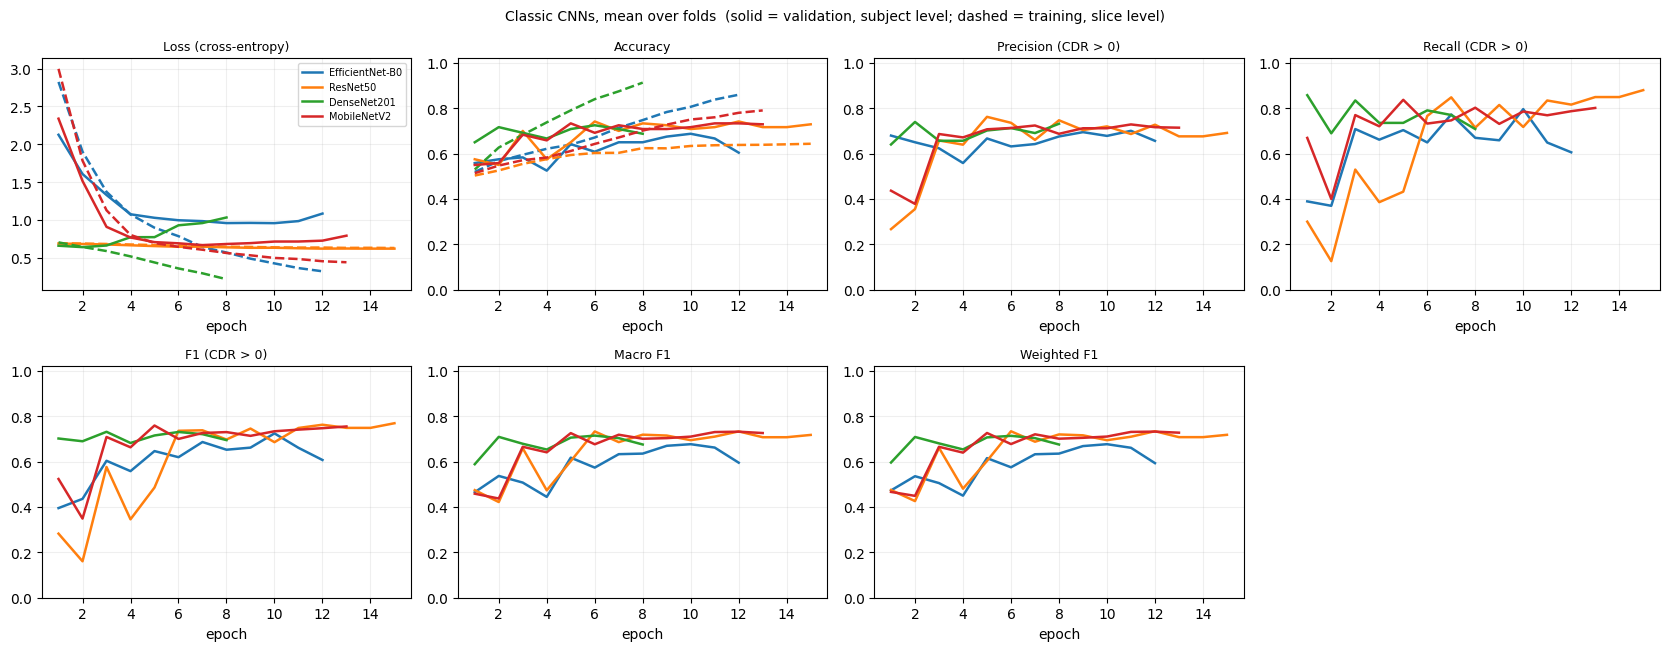

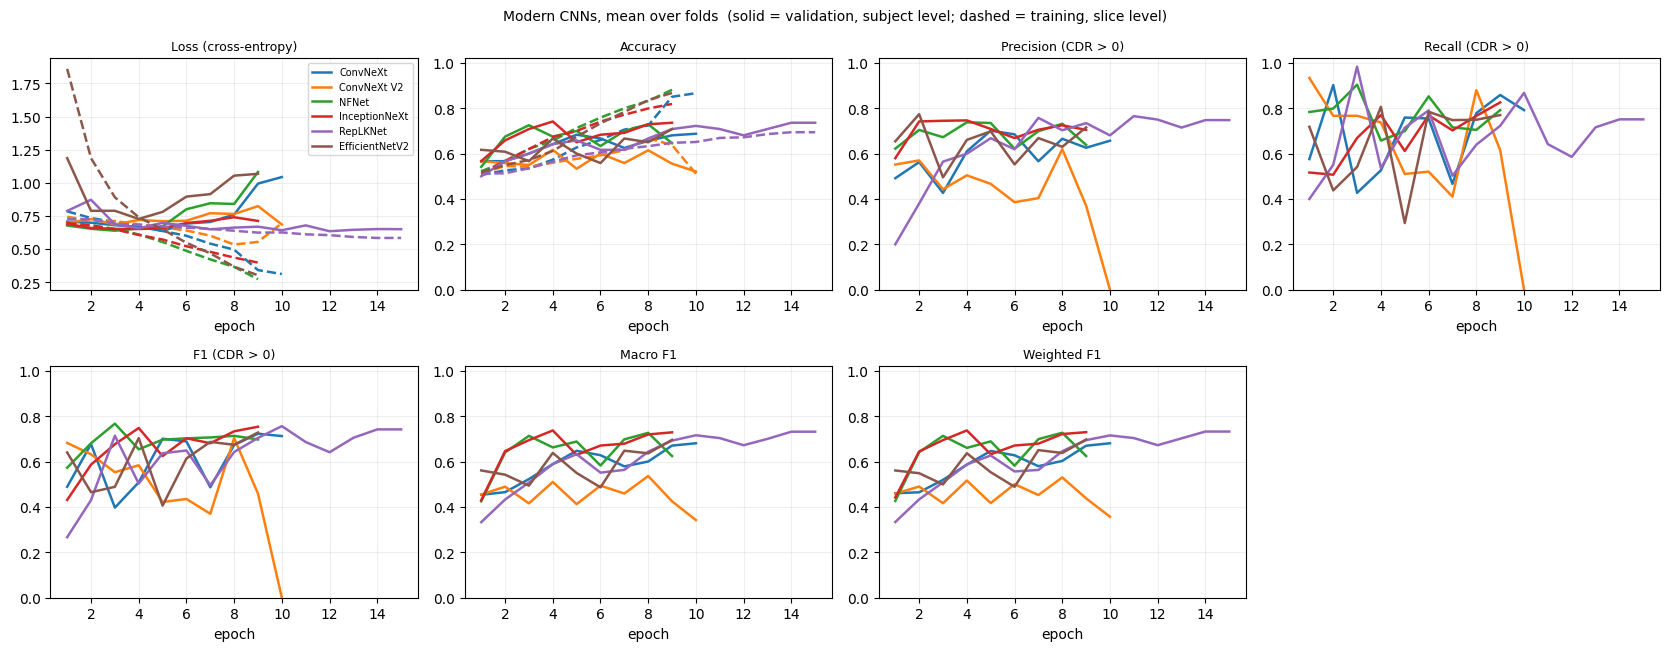

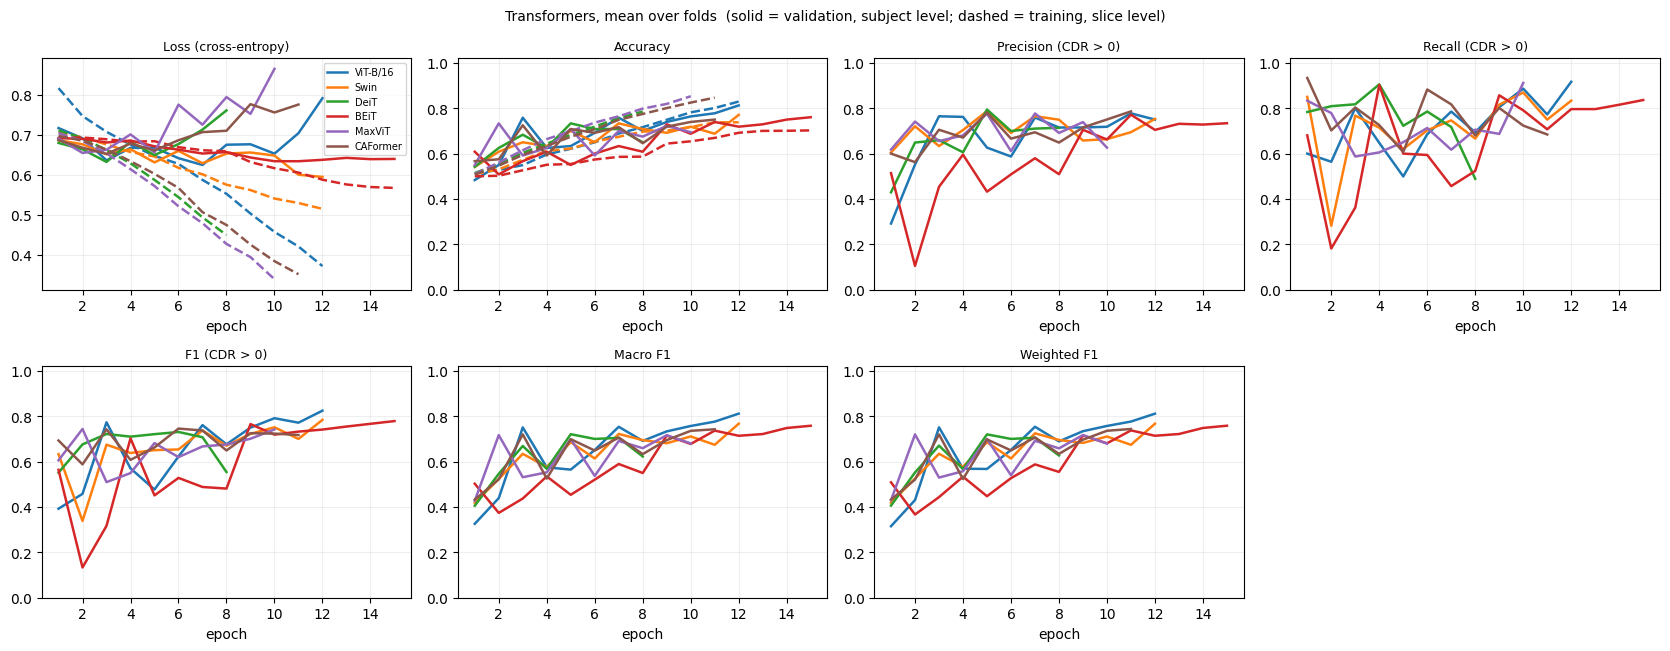

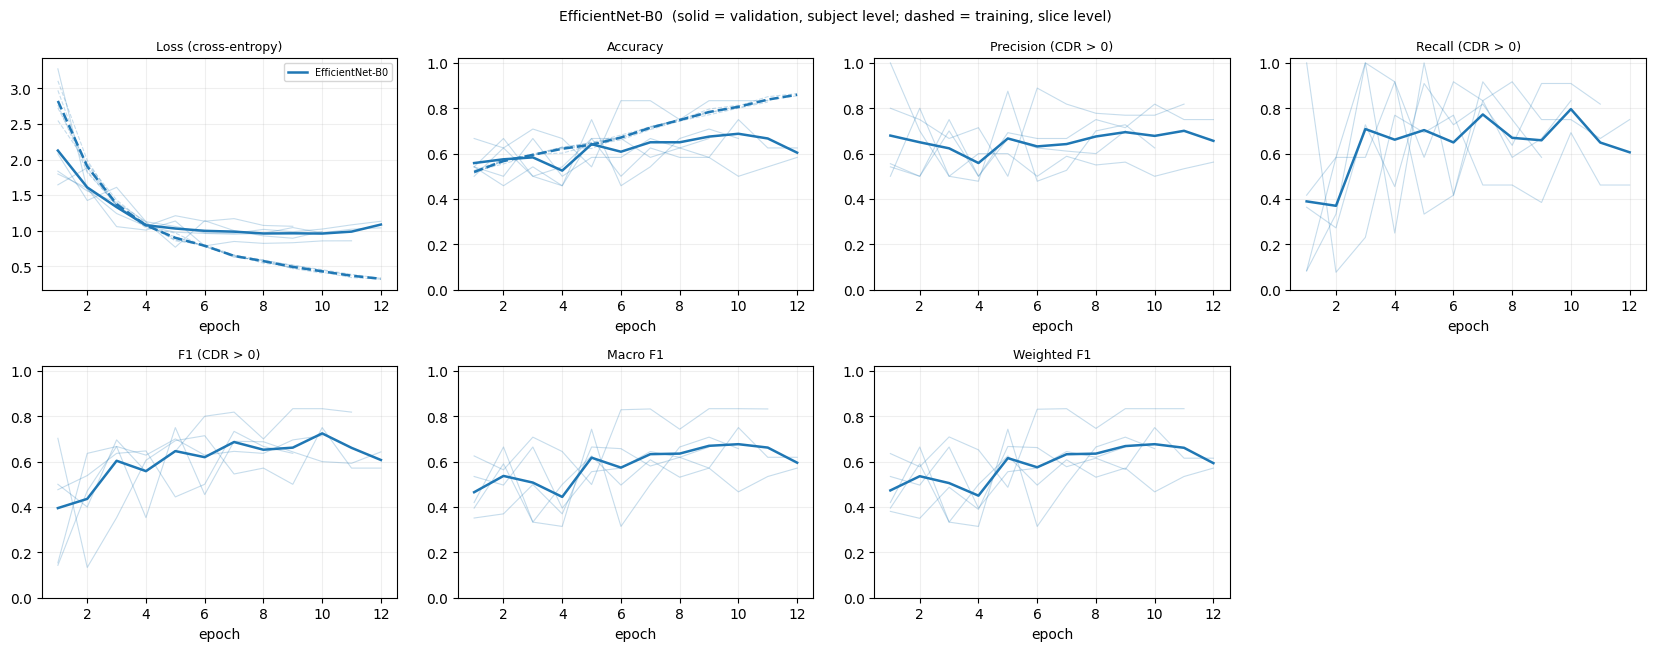

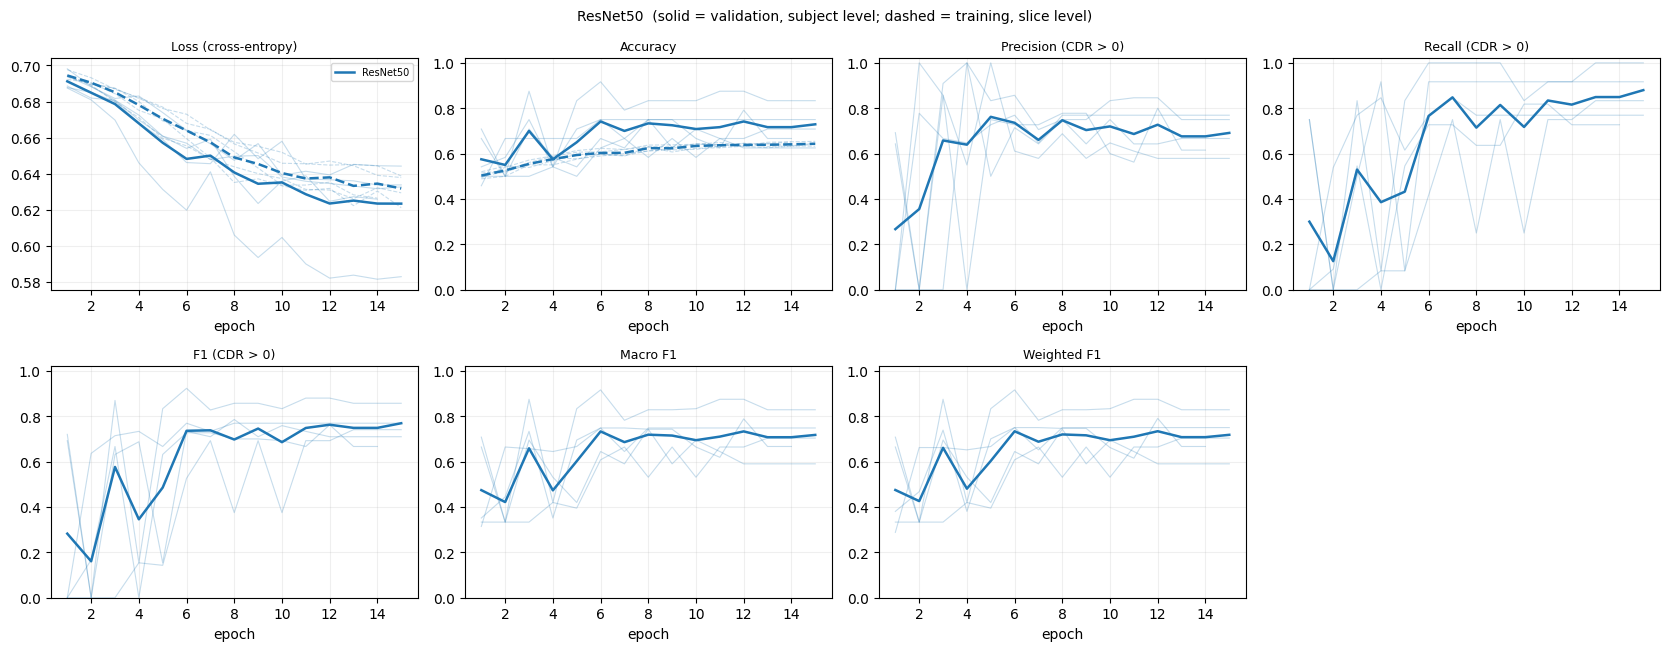

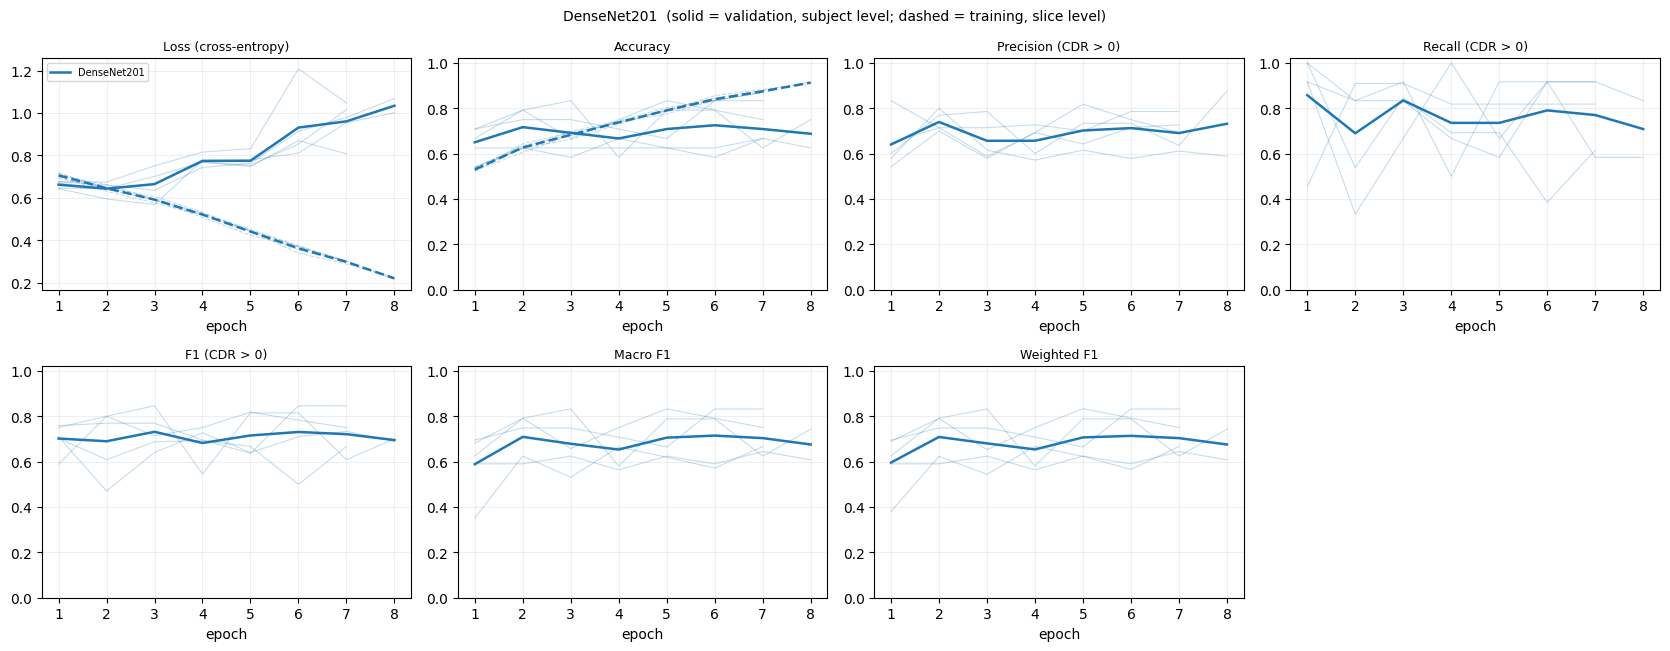

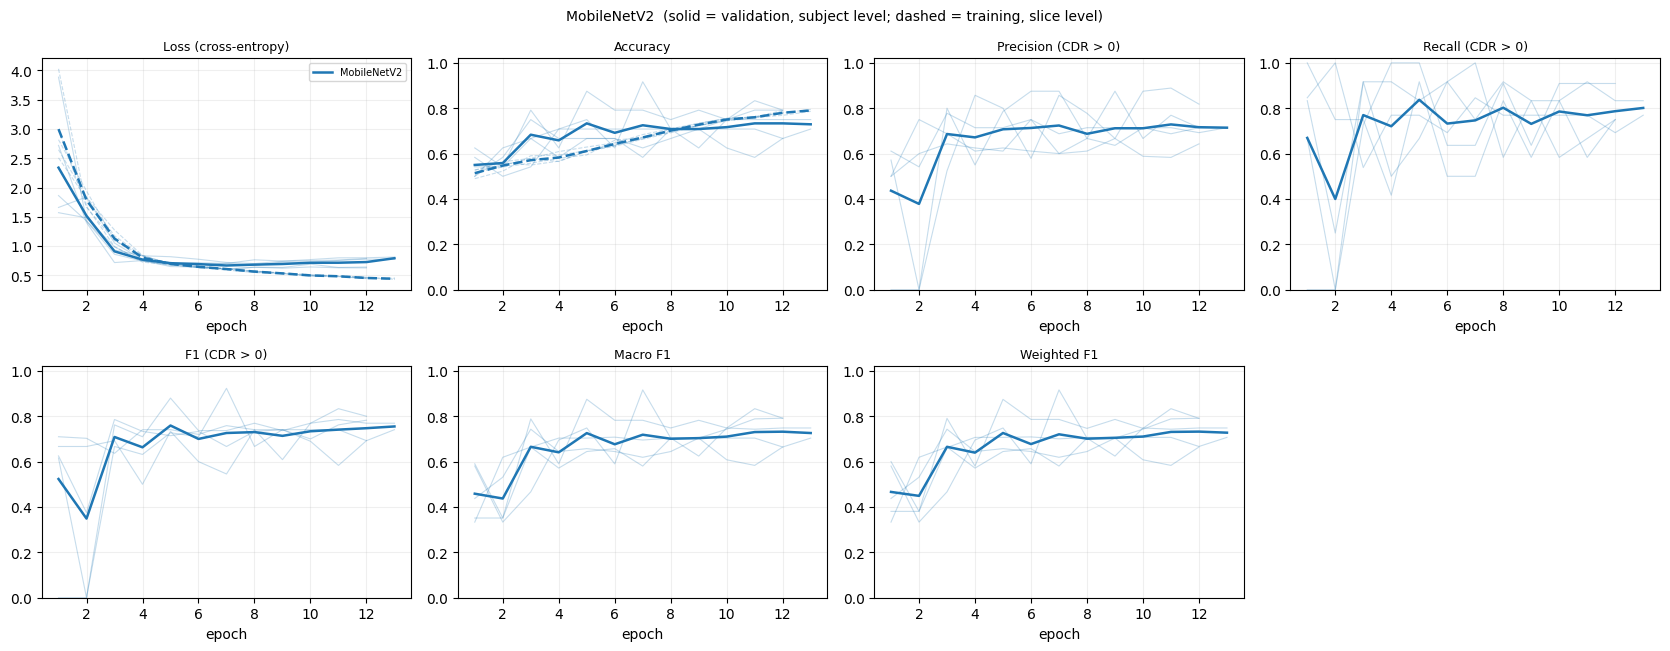

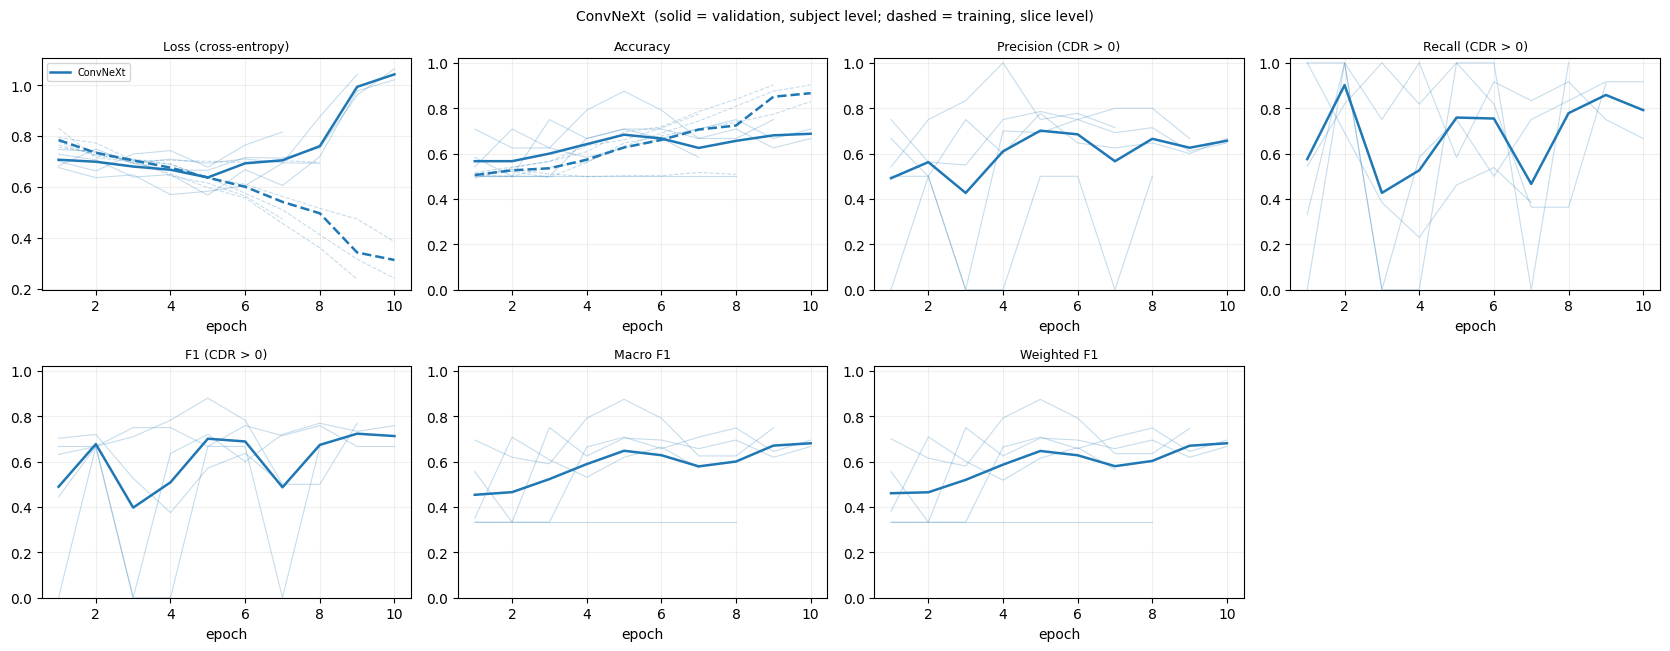

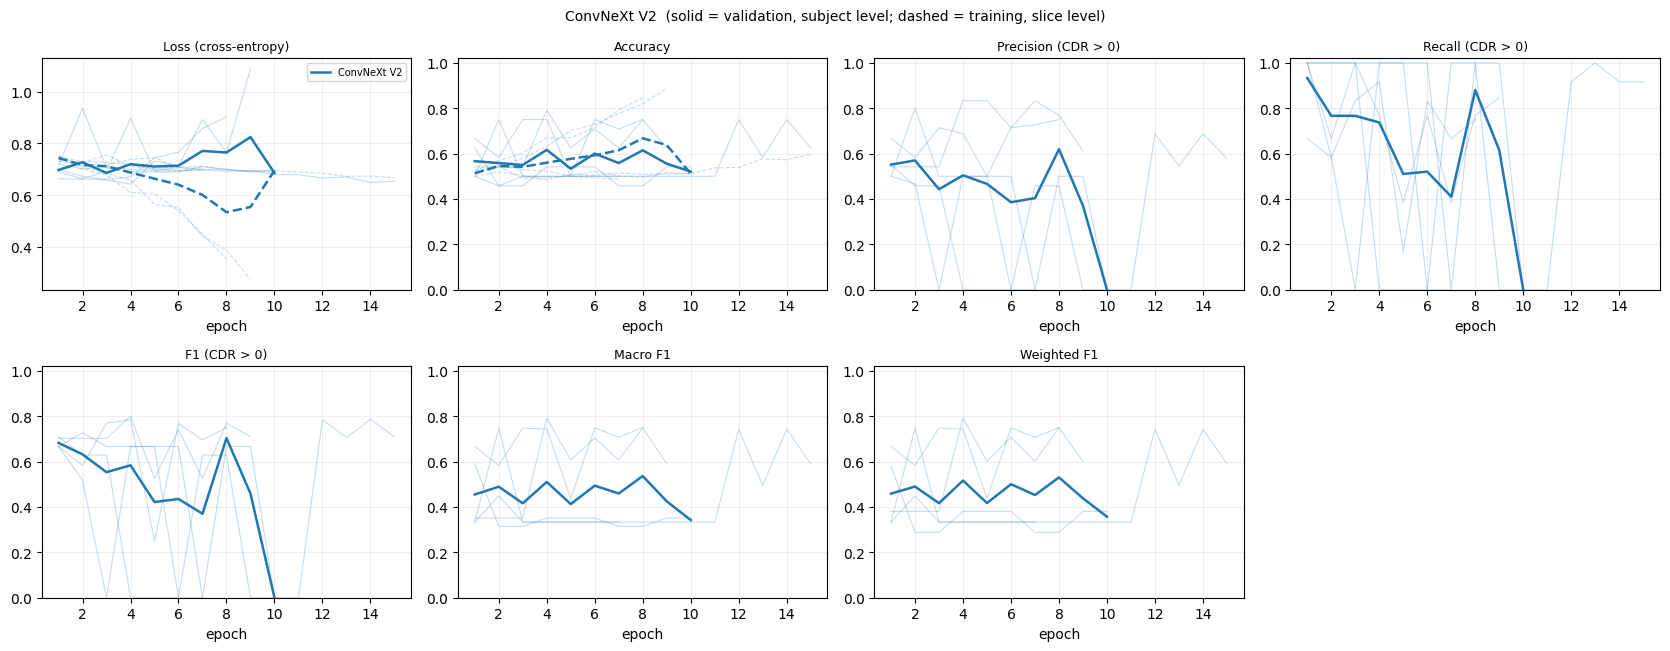

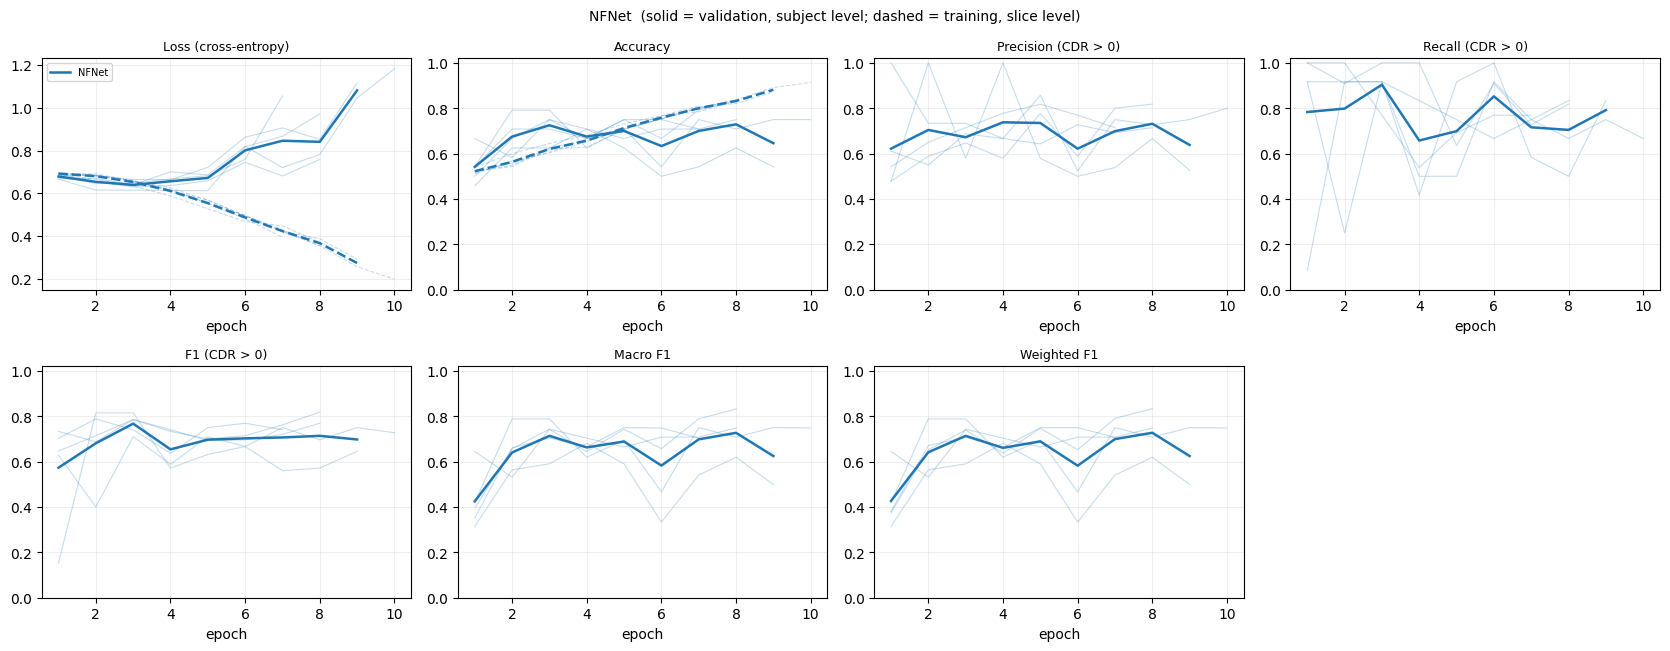

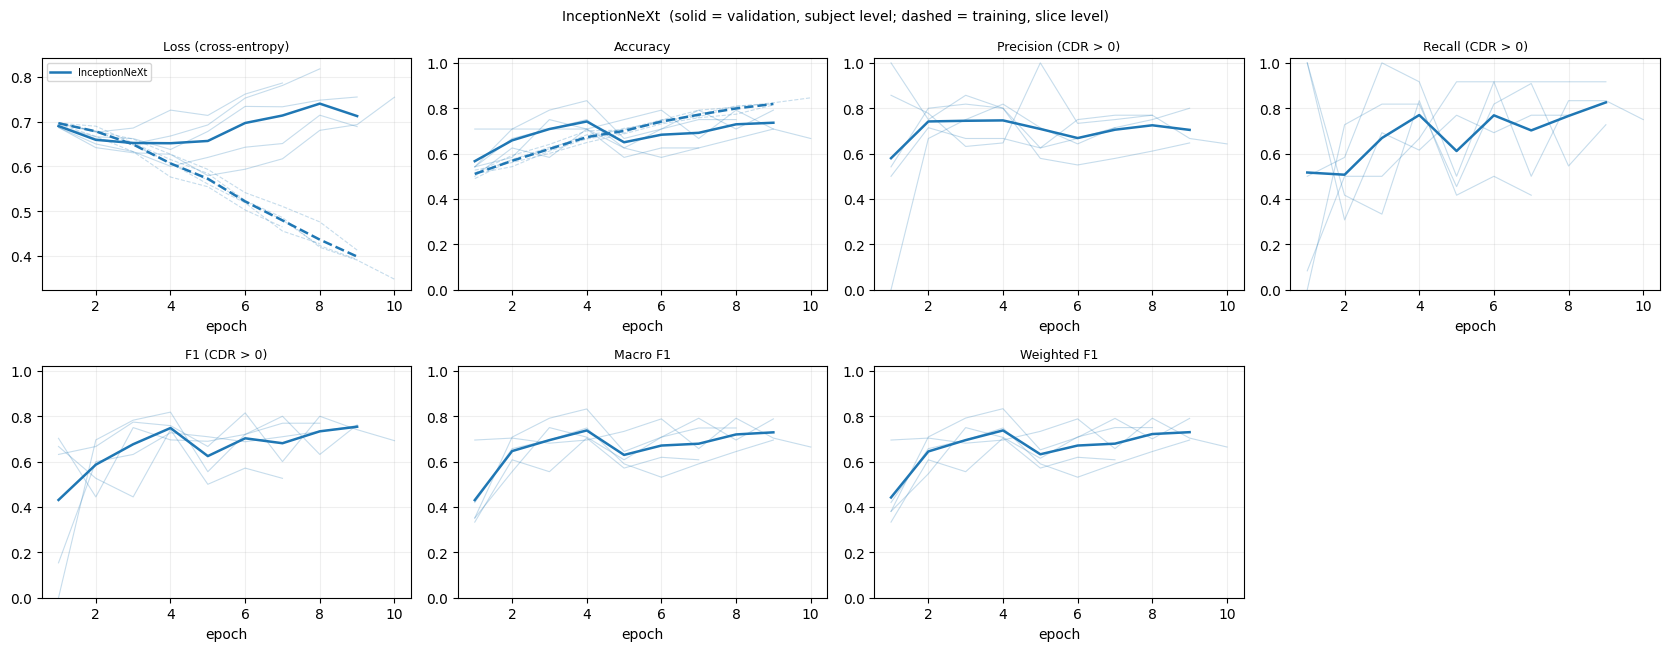

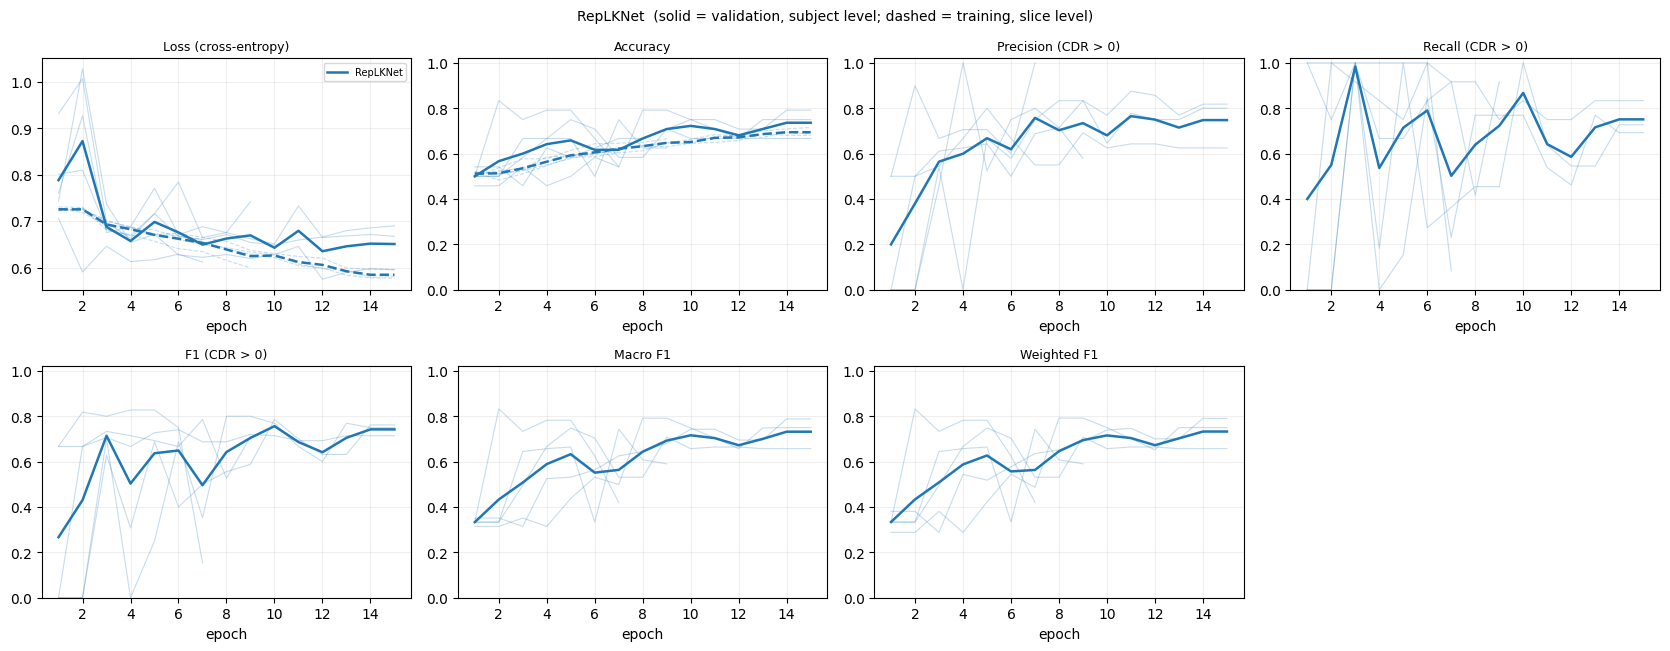

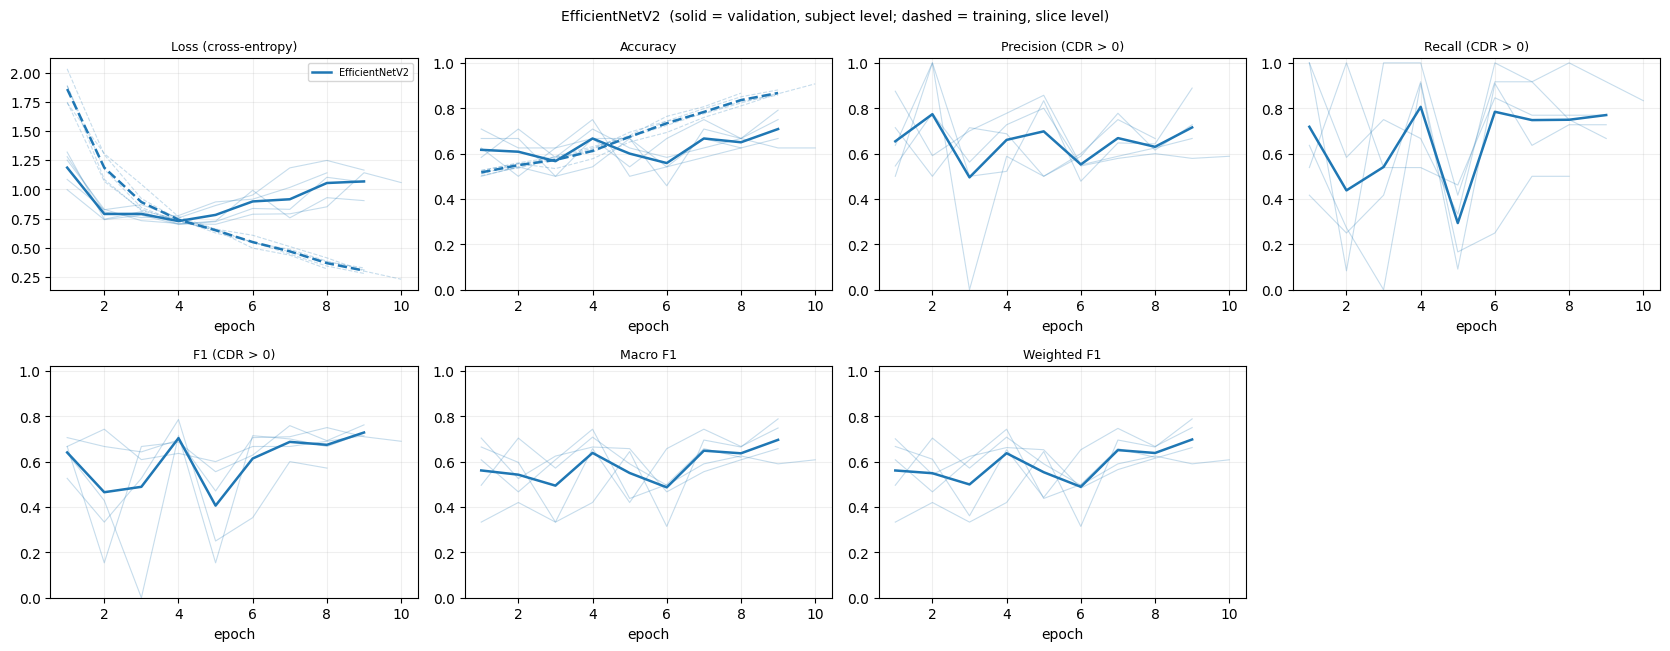

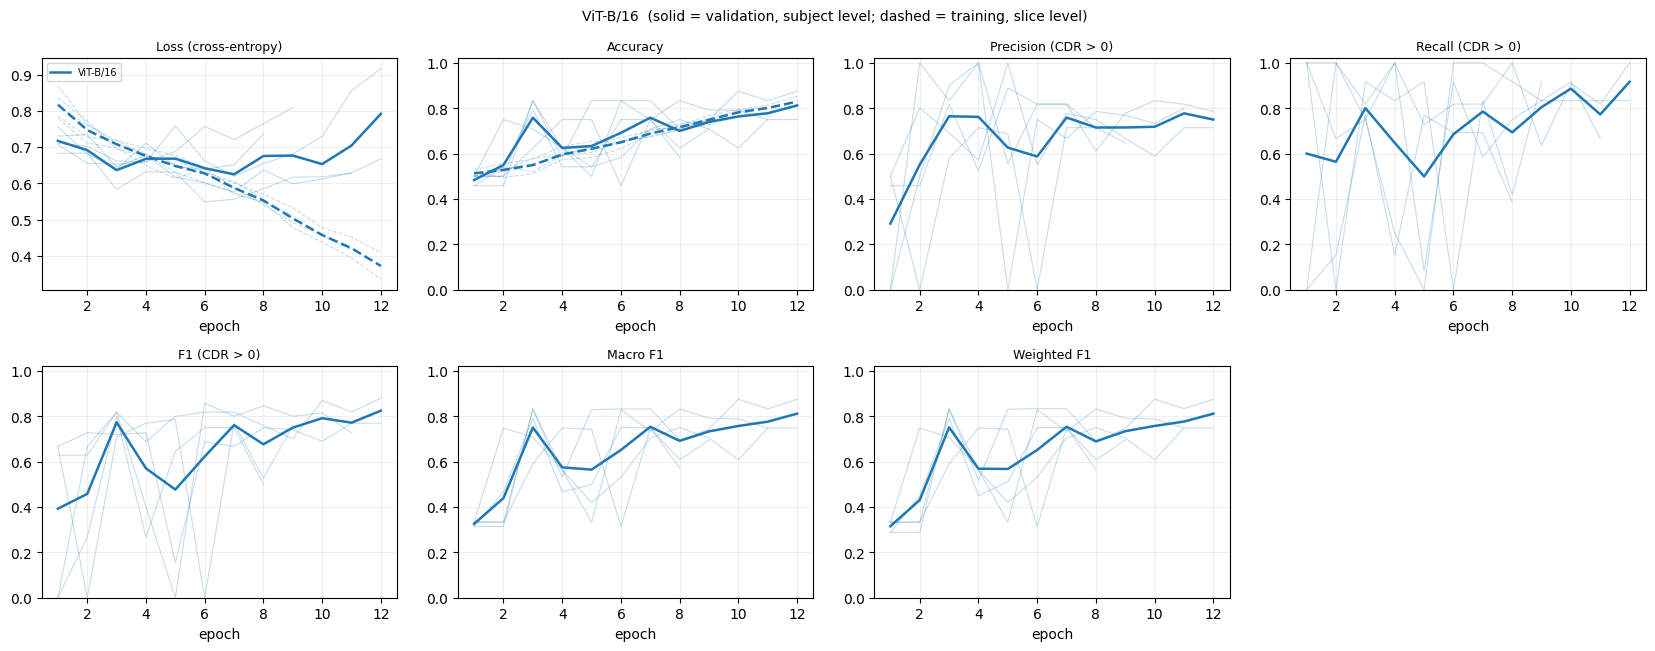

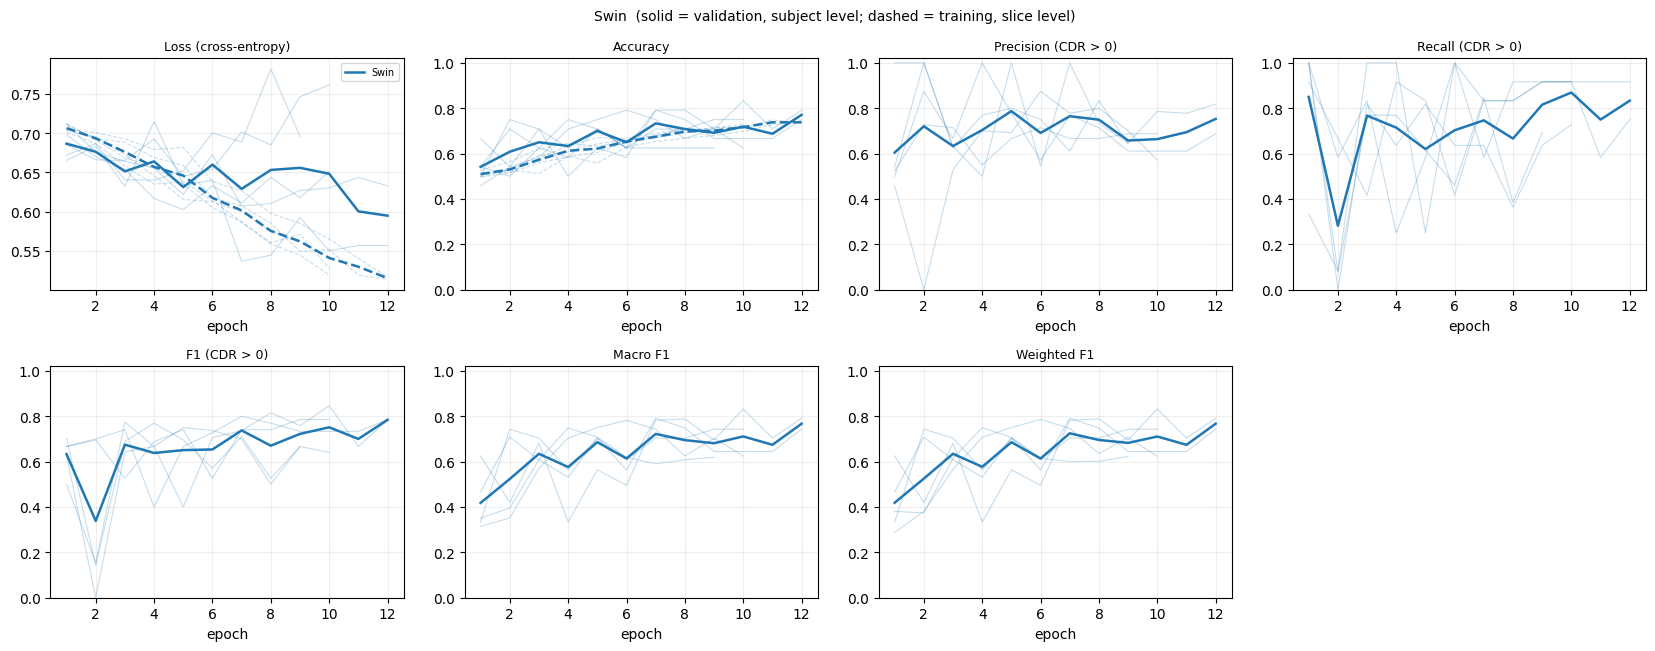

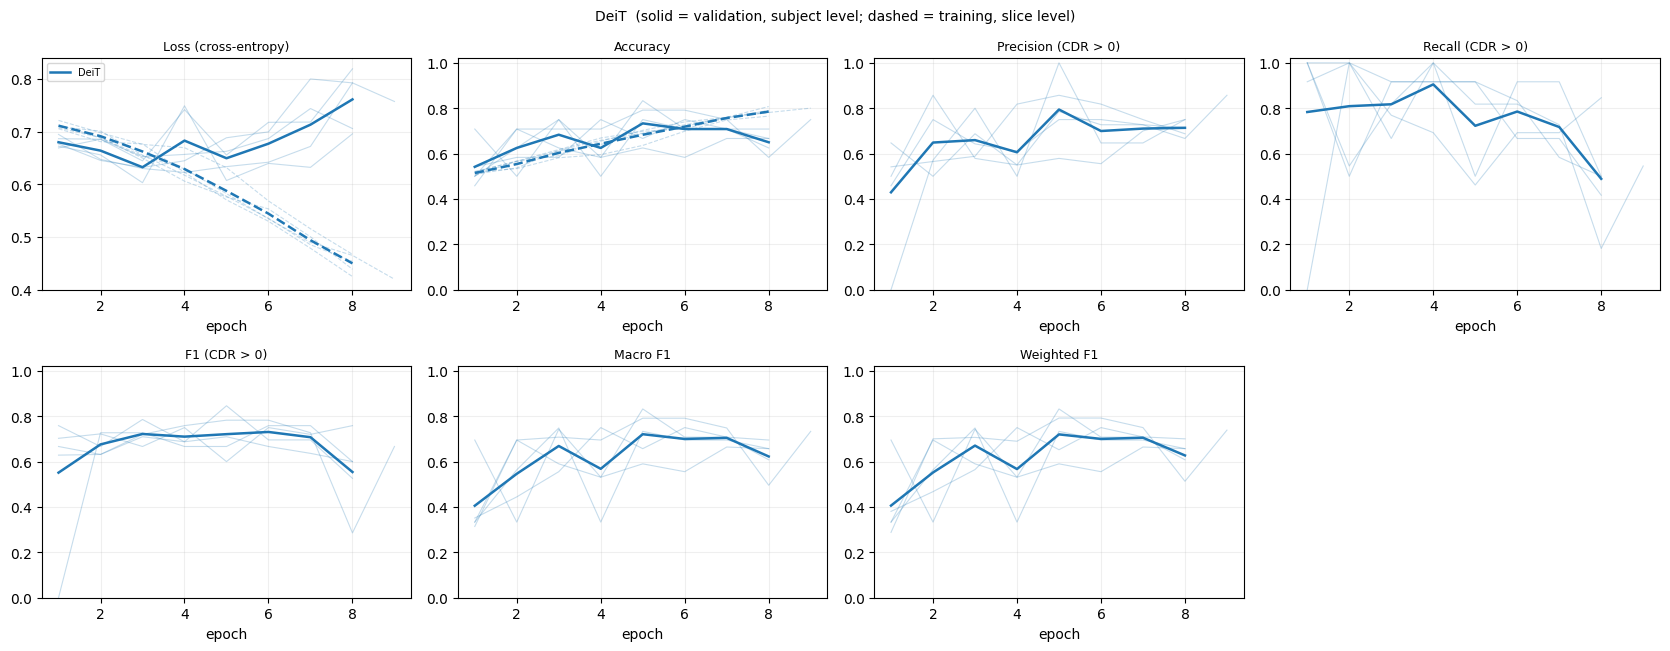

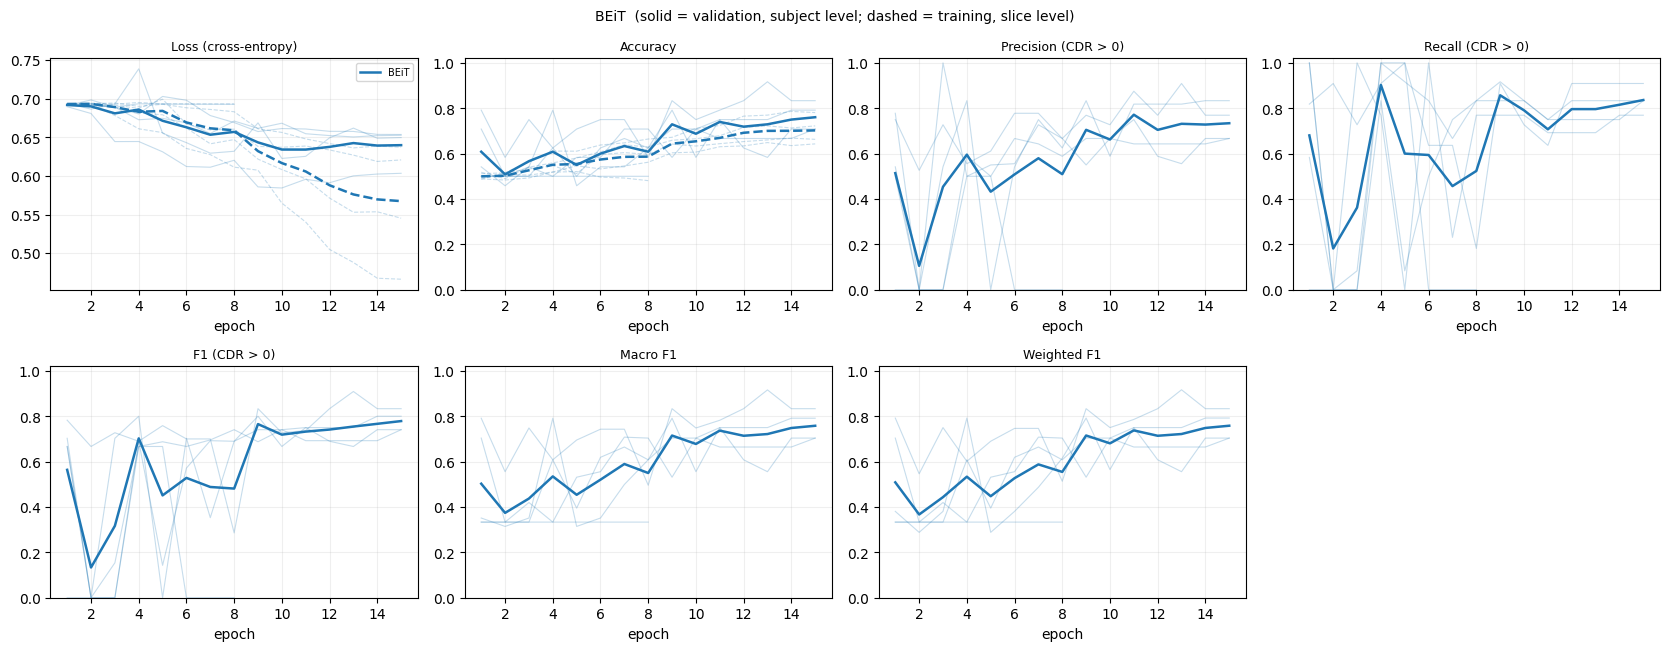

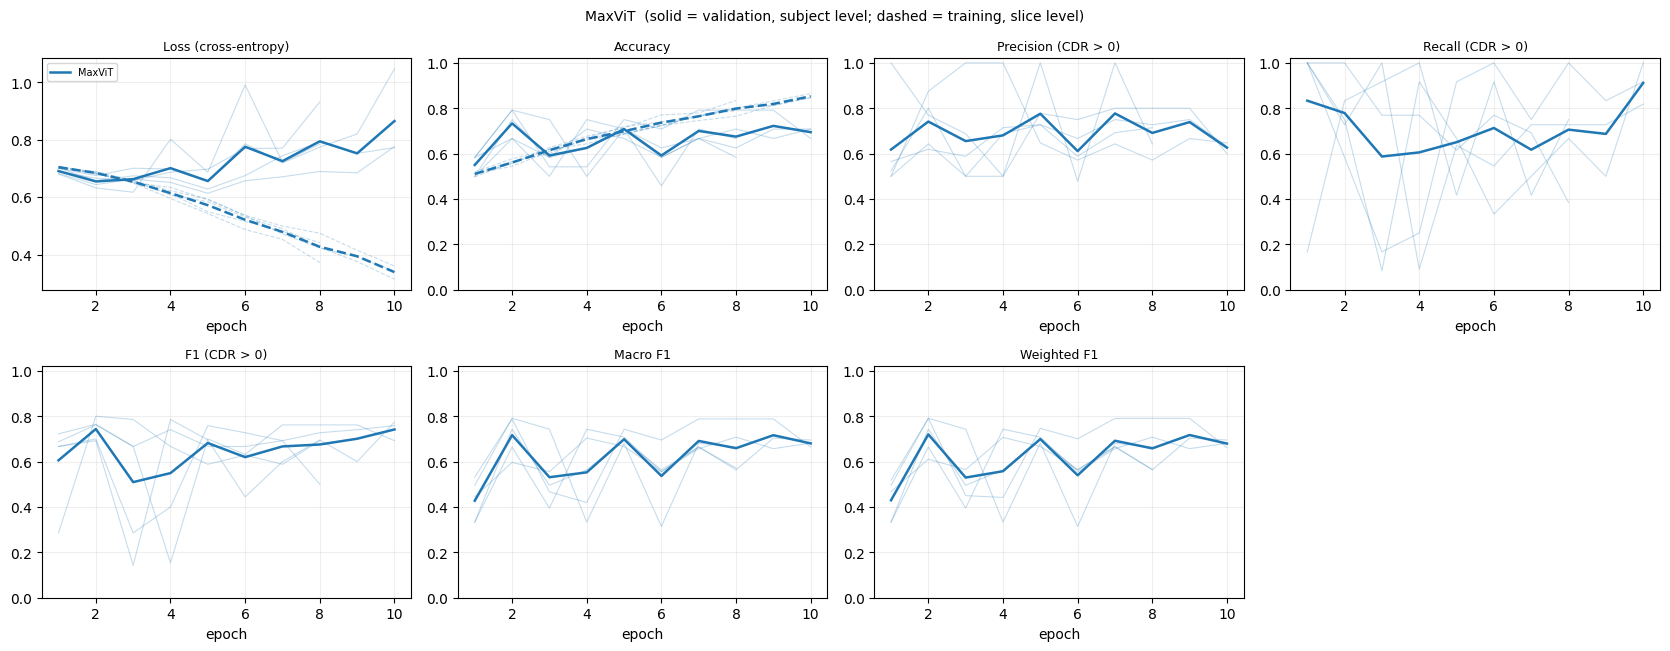

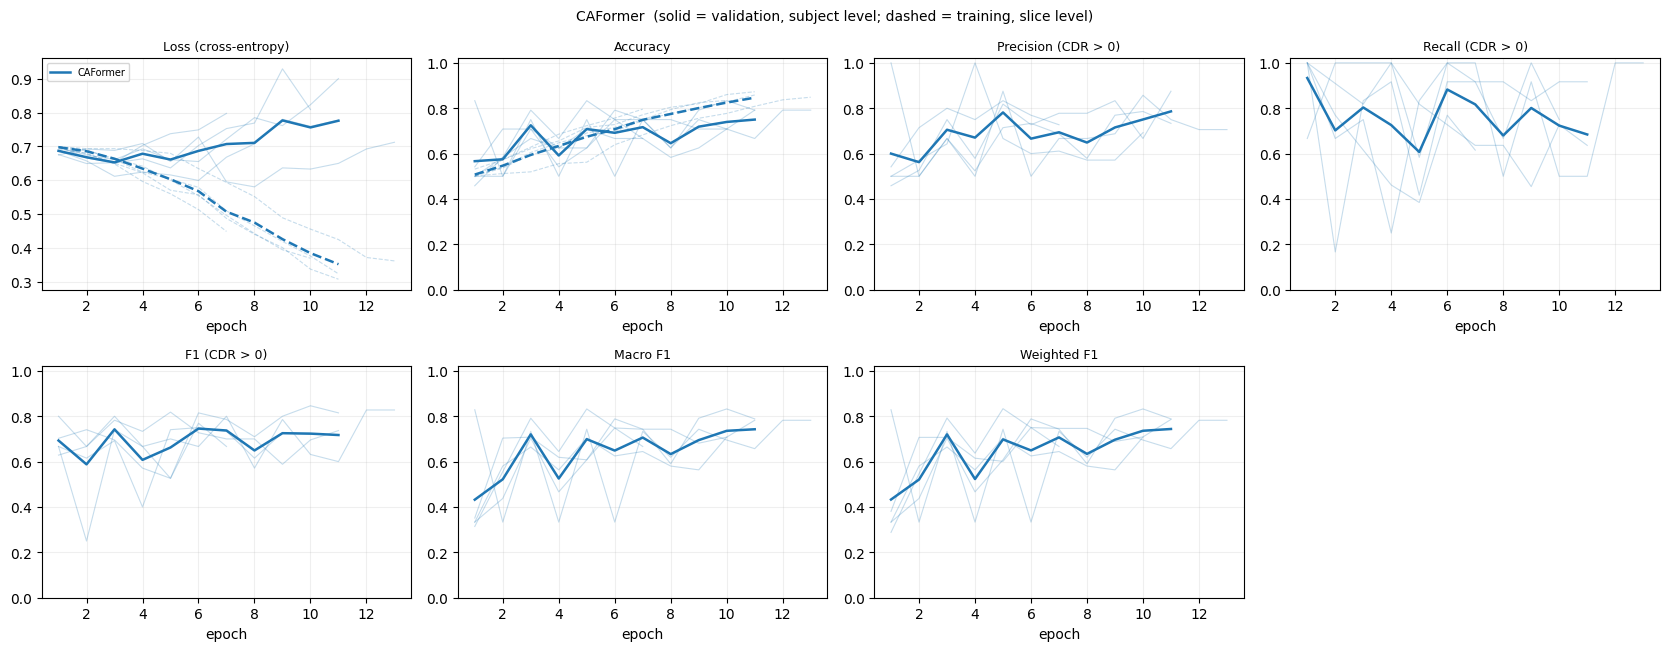

In [9]:
H = pd.concat([pd.read_csv(p) for p in sorted(OUT_DIR.glob(f"{TASK}_*_history.csv"))], ignore_index=True)
H = H[H.data_id == DATA_ID]                                    # ignore results from other data versions
assert len(H), "no history files for the current data: run section 5 first"
order_h = [m for m in MODELS if m in set(H.model)]

HIST_METRICS = [("val_loss", "Loss (cross-entropy)", "train_loss"),
                ("val_acc", "Accuracy", "train_acc"),
                ("val_precision", "Precision (CDR > 0)" if N_CLASSES == 2 else "Precision (macro)", None),
                ("val_recall", "Recall (CDR > 0)" if N_CLASSES == 2 else "Recall (macro)", None)]
if N_CLASSES == 2:
    HIST_METRICS.append(("val_f1", "F1 (CDR > 0)", None))
HIST_METRICS += [("val_f1_macro", "Macro F1", None), ("val_f1_weighted", "Weighted F1", None)]

def curves_grid(H, models, per_fold, fname, title):
    ncols = 4; nrows = int(np.ceil(len(HIST_METRICS) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.3 * nrows)); axes = axes.ravel()
    for ax, (col, ttl, tcol) in zip(axes, HIST_METRICS):
        for i, m in enumerate(models):
            d, c = H[H.model == m], f"C{i}"
            if per_fold:
                for _, dk in d.groupby("fold"):
                    ax.plot(dk.epoch, dk[col], c=c, alpha=0.25, lw=0.8)
                    if tcol: ax.plot(dk.epoch, dk[tcol], c=c, alpha=0.25, lw=0.8, ls="--")
            need = min(2, d.fold.nunique())                      # mean only where at least 2 folds are still training
            for column, ls, lab in [(col, "-", m)] + ([(tcol, "--", None)] if tcol else []):
                g = d.groupby("epoch")[column]
                mean = g.mean()[g.count() >= need]
                ax.plot(mean.index, mean.values, c=c, lw=1.8, ls=ls, label=lab)
        ax.set_title(ttl, fontsize=9); ax.set_xlabel("epoch"); ax.grid(alpha=0.2)
        if col != "val_loss": ax.set_ylim(0, 1.02)
    for ax in axes[len(HIST_METRICS):]: ax.axis("off")
    axes[0].legend(fontsize=7)
    fig.suptitle(title + "  (solid = validation, subject level; dashed = training, slice level)", fontsize=10)
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=150); plt.show()

for gname, ms in by_group(order_h):
    curves_grid(H, ms, False, f"{TASK}_curves_{gname.replace(' ', '_')}.png", f"{gname}, mean over folds")
for m in order_h:
    curves_grid(H, [m], True, f"{TASK}_curves_{m.replace('/', '-').replace(' ', '_')}.png", m)
H.to_csv(OUT_DIR / f"{TASK}_training_history_all.csv", index=False)

## 6. Results

Tables and plots are split by group (Classic CNNs, Modern CNNs, Transformers).

Mean and standard deviation over the 5 test folds, computed on subject-level predictions. The dashed line is the best tabular baseline (age + nWBV) from the data-preparation notebook, which is the bar an image model has to beat.

In [10]:
res = pd.DataFrame([json.load(open(p)) for p in sorted(OUT_DIR.glob(f"{TASK}_*_fold*.json"))])
if "data_id" not in res.columns: res["data_id"] = None
res = res[res.data_id == DATA_ID]                              # ignore results from other data versions
assert len(res), "no results for the current data: run the previous cell first"
order = [m for m in MODELS if m in set(res.model)]
cols = ["auc", "bal_acc", "acc", "f1"] + (["sens", "spec"] if N_CLASSES == 2 else [])

agg = res.groupby("model")[cols].agg(["mean", "std"]).loc[order]
summary = pd.DataFrame({"model": order})
for c in cols:
    summary[c] = [f"{agg.loc[m, (c, 'mean')]:.3f} \u00b1 {agg.loc[m, (c, 'std')]:.3f}" for m in order]
info = res.groupby("model").agg(params_M=("n_params_m", "first"), min_per_fold=("minutes", "mean"),
                                best_epoch=("best_epoch", "mean"), pretrained=("pretrained_loaded", "all")).loc[order]
summary = summary.merge(info.reset_index(), on="model")
summary.insert(1, "group", summary.model.map(GROUP_OF))
for gname, ms in by_group(order):
    print(f"\n--- {gname} ---")
    print(summary[summary.model.isin(ms)].drop(columns="group").round(2).to_string(index=False))
summary.to_csv(OUT_DIR / f"{TASK}_image_baselines_summary.csv", index=False)

print("\nAUC per fold:")
print(res.pivot(index="model", columns="fold", values="auc").loc[order].round(3))

ref = None
tab = DATA_DIR / "tabular_baselines.csv"
if tab.exists() and TASK == "binary":
    t = pd.read_csv(tab); ref = float(t.loc[t.features == "Age + nWBV", "auc_mean"].iloc[0])
    print(f"\nTabular reference (Age + nWBV) AUC: {ref:.3f}")


--- Classic CNNs ---
          model           auc       bal_acc           acc            f1          sens          spec  params_M  min_per_fold  best_epoch  pretrained
EfficientNet-B0 0.731 ± 0.080 0.657 ± 0.108 0.661 ± 0.095 0.642 ± 0.147 0.640 ± 0.205 0.673 ± 0.239       4.0          1.16         5.8        True
       ResNet50 0.730 ± 0.046 0.690 ± 0.070 0.691 ± 0.081 0.711 ± 0.099 0.773 ± 0.069 0.608 ± 0.086      23.5          2.46        12.2        True
    DenseNet201 0.734 ± 0.046 0.674 ± 0.060 0.677 ± 0.072 0.660 ± 0.106 0.655 ± 0.155 0.693 ± 0.086      18.1          2.14         2.4        True
    MobileNetV2 0.723 ± 0.034 0.673 ± 0.036 0.666 ± 0.040 0.664 ± 0.065 0.673 ± 0.113 0.673 ± 0.117       2.2          1.06         7.4        True

--- Modern CNNs ---
         model           auc       bal_acc           acc            f1          sens          spec  params_M  min_per_fold  best_epoch  pretrained
      ConvNeXt 0.688 ± 0.027 0.592 ± 0.068 0.591 ± 0.057 0.455 ± 0.276

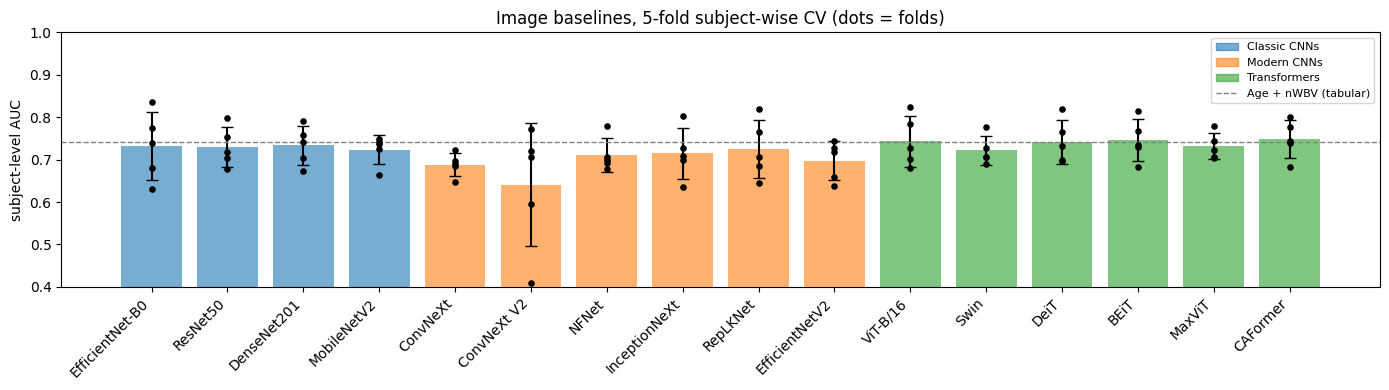

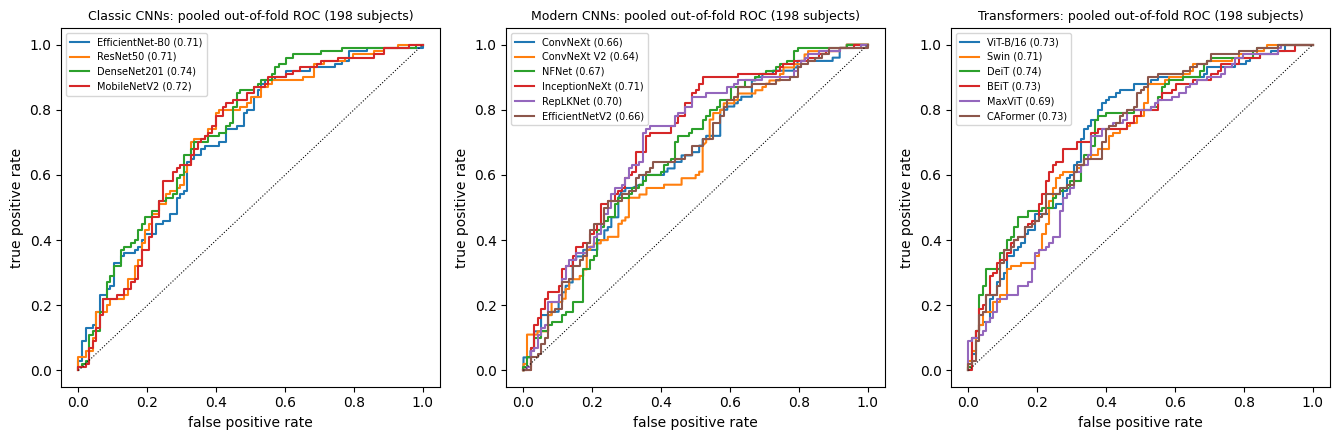

In [11]:
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(max(7, 0.75 * len(order) + 2), 4))
for i, m in enumerate(order):
    v = res.loc[res.model == m].sort_values("fold").auc.values
    ax.bar(i, v.mean(), yerr=v.std(ddof=1) if len(v) > 1 else 0, alpha=0.6, capsize=4, color=GROUP_COLORS[GROUP_OF[m]])
    ax.scatter(np.full(len(v), i), v, c="k", s=14, zorder=3)
if ref is not None:
    ax.axhline(ref, ls="--", c="grey", lw=1, label="Age + nWBV (tabular)")
h0, _ = ax.get_legend_handles_labels()
ax.legend(handles=[Patch(color=GROUP_COLORS[g], alpha=0.6, label=g) for g, _ in by_group(order)] + h0, fontsize=8)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=45, ha="right")
ax.set_ylabel("subject-level AUC"); ax.set_ylim(0.4, 1.0)
ax.set_title("Image baselines, 5-fold subject-wise CV (dots = folds)")
plt.tight_layout(); plt.savefig(OUT_DIR / f"{TASK}_auc_by_model.png", dpi=150); plt.show()

if N_CLASSES == 2:
    oof = pd.concat([pd.read_csv(p) for p in sorted(OUT_DIR.glob(f"{TASK}_*_preds.csv"))])
    grp = by_group(order)
    fig, axs = panel_axes(len(grp), w=4.5, h=4.5)
    for ax, (gname, ms) in zip(axs, grp):
        for m in ms:
            d = oof[oof.model == m]
            fpr, tpr, _ = roc_curve(d.y, d.p1)
            ax.plot(fpr, tpr, label=f"{m} ({roc_auc_score(d.y, d.p1):.2f})")
        ax.plot([0, 1], [0, 1], "k:", lw=0.8)
        ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
        ax.set_title(f"{gname}: pooled out-of-fold ROC (198 subjects)", fontsize=9); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(OUT_DIR / f"{TASK}_roc_pooled.png", dpi=150); plt.show()

## 6b. Precision, recall, F1 and the classification report

Computed from the **subject-level out-of-fold predictions** saved in section 5 (`*_preds.csv`), with the same decision rule as `metrics()` (binary: p1 >= 0.5, three-class: argmax).

- **Table:** precision, recall, macro F1 and weighted F1 per fold, then mean ± std over the 5 folds (same style as section 6). In the binary task, precision and recall are for the positive class (CDR > 0). Macro averages every class equally, weighted averages by class size.
- **Classification report:** one per model, on all subjects pooled over the 5 test folds.

In [12]:
from sklearn.metrics import (precision_score, recall_score, classification_report,
                             precision_recall_curve, average_precision_score)

CLASS_NAMES = ["CDR 0", "CDR > 0"] if N_CLASSES == 2 else ["CDR 0", "CDR 0.5", "CDR 1+"]
LABELS = list(range(N_CLASSES))
PCOLS = [f"p{c}" for c in range(N_CLASSES)]

# out-of-fold subject predictions saved in section 5 (one row per subject and model)
oof_g = pd.concat([pd.read_csv(p) for p in sorted(OUT_DIR.glob(f"{TASK}_*_preds.csv"))], ignore_index=True)
oof_g = oof_g[oof_g.model.isin(order)]

def hard_pred(d):
    P = d[PCOLS].values
    return (P[:, 1] >= 0.5).astype(int) if N_CLASSES == 2 else P.argmax(1)     # same rule as metrics()

# ---- per fold ----
rows = []
for (m, k), d in oof_g.groupby(["model", "fold"]):
    yt, yh = d.y.values, hard_pred(d)
    r = dict(model=m, fold=k)
    if N_CLASSES == 2:                                         # positive class = CDR > 0
        r["precision"] = precision_score(yt, yh, pos_label=1, zero_division=0)
        r["recall"]    = recall_score(yt, yh, pos_label=1, zero_division=0)
    r["precision_macro"] = precision_score(yt, yh, labels=LABELS, average="macro", zero_division=0)
    r["recall_macro"]    = recall_score(yt, yh, labels=LABELS, average="macro", zero_division=0)
    r["f1_macro"]        = f1_score(yt, yh, labels=LABELS, average="macro", zero_division=0)
    r["f1_weighted"]     = f1_score(yt, yh, labels=LABELS, average="weighted", zero_division=0)
    rows.append(r)
fold_m = pd.DataFrame(rows)
fold_m.insert(1, "group", fold_m.model.map(GROUP_OF))
fold_m.to_csv(OUT_DIR / f"{TASK}_image_prf_per_fold.csv", index=False)

# ---- mean ± std over folds ----
mcols = [c for c in fold_m.columns if c not in ("model", "group", "fold")]
agg2 = fold_m.groupby("model")[mcols].agg(["mean", "std"]).loc[order]
prf = pd.DataFrame({"model": order})
prf.insert(1, "group", prf.model.map(GROUP_OF))
for c in mcols:
    prf[c] = [f"{agg2.loc[m, (c, 'mean')]:.3f} \u00b1 {agg2.loc[m, (c, 'std')]:.3f}" for m in order]
print("Mean \u00b1 std over the test folds (subject level):")
for gname, ms in by_group(order):
    print(f"\n--- {gname} ---")
    print(prf[prf.model.isin(ms)].drop(columns="group").to_string(index=False))
prf.to_csv(OUT_DIR / f"{TASK}_image_prf_summary.csv", index=False)

# ---- pooled classification report, one per model ----
print("\nClassification report, all test subjects pooled over the folds")
texts = []
for gname, ms in by_group(order):
    for m in ms:
        d = oof_g[oof_g.model == m].sort_values("subject")
        txt = classification_report(d.y.values, hard_pred(d), labels=LABELS, target_names=CLASS_NAMES,
                                    digits=3, zero_division=0)
        texts.append(f"=== {gname} | {m} ===\n{txt}")
        print(f"\n=== {gname} | {m} ===\n{txt}")
(OUT_DIR / f"{TASK}_image_classification_reports.txt").write_text("\n".join(texts))

Mean ± std over the test folds (subject level):

--- Classic CNNs ---
          model     precision        recall precision_macro  recall_macro      f1_macro   f1_weighted
EfficientNet-B0 0.674 ± 0.170 0.640 ± 0.205   0.669 ± 0.103 0.657 ± 0.108 0.642 ± 0.109 0.650 ± 0.106
       ResNet50 0.662 ± 0.125 0.773 ± 0.069   0.695 ± 0.074 0.690 ± 0.070 0.685 ± 0.077 0.690 ± 0.080
    DenseNet201 0.681 ± 0.091 0.655 ± 0.155   0.680 ± 0.062 0.674 ± 0.060 0.669 ± 0.066 0.674 ± 0.073
    MobileNetV2 0.677 ± 0.121 0.673 ± 0.113   0.675 ± 0.040 0.673 ± 0.036 0.663 ± 0.037 0.666 ± 0.039

--- Modern CNNs ---
         model     precision        recall precision_macro  recall_macro      f1_macro   f1_weighted
      ConvNeXt 0.512 ± 0.307 0.437 ± 0.298   0.548 ± 0.165 0.592 ± 0.068 0.546 ± 0.122 0.552 ± 0.119
   ConvNeXt V2 0.484 ± 0.288 0.501 ± 0.301   0.543 ± 0.213 0.607 ± 0.099 0.559 ± 0.178 0.547 ± 0.206
         NFNet 0.639 ± 0.142 0.609 ± 0.270   0.626 ± 0.068 0.593 ± 0.040 0.570 ± 0.038 0.581 ± 0

5747

## 6c. Precision-recall curve

Pooled out-of-fold subject probabilities, one curve per model. AP is average precision (area under the PR curve). The dotted line is a model with no skill, which sits at the share of positive subjects. The binary task has one plot (positive class = CDR > 0); the three-class task has one plot per class (one-vs-rest).

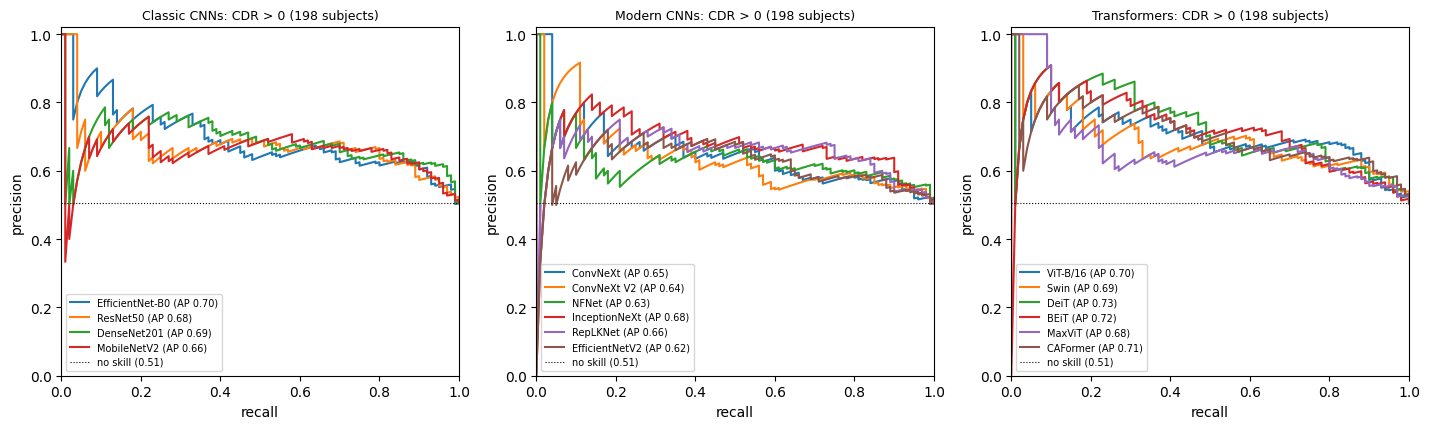

Average precision (pooled out-of-fold):

--- Classic CNNs ---
positive_class   CDR > 0
model                   
EfficientNet-B0    0.697
ResNet50           0.676
DenseNet201        0.689
MobileNetV2        0.662

--- Modern CNNs ---
positive_class  CDR > 0
model                  
ConvNeXt          0.651
ConvNeXt V2       0.641
NFNet             0.632
InceptionNeXt     0.676
RepLKNet          0.659
EfficientNetV2    0.623

--- Transformers ---
positive_class  CDR > 0
model                  
ViT-B/16          0.704
Swin              0.690
DeiT              0.728
BEiT              0.717
MaxViT            0.676
CAFormer          0.708


In [13]:
classes = [1] if N_CLASSES == 2 else LABELS
grp = by_group(order)
ap_rows = []
for c in classes:
    fig, axs = panel_axes(len(grp))
    for ax, (gname, ms) in zip(axs, grp):
        for m in ms:
            d = oof_g[oof_g.model == m]
            yb, sc = (d.y.values == c).astype(int), d[f"p{c}"].values
            pr, rc, _ = precision_recall_curve(yb, sc)
            ap = average_precision_score(yb, sc)
            ax.plot(rc, pr, label=f"{m} (AP {ap:.2f})")
            ap_rows.append(dict(model=m, positive_class=CLASS_NAMES[c], AP=ap))
        ax.axhline(yb.mean(), ls=":", c="k", lw=0.8, label=f"no skill ({yb.mean():.2f})")
        ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
        ax.set_title(f"{gname}: {CLASS_NAMES[c]} ({len(d)} subjects)", fontsize=9)
        ax.legend(fontsize=7, loc="lower left")
    plt.tight_layout()
    plt.savefig(OUT_DIR / (f"{TASK}_image_pr_pooled" + ("" if N_CLASSES == 2 else f"_class{c}") + ".png"), dpi=150)
    plt.show()

ap_tab = pd.DataFrame(ap_rows).pivot(index="model", columns="positive_class", values="AP").loc[order]
ap_tab.insert(0, "group", ap_tab.index.map(GROUP_OF))
print("Average precision (pooled out-of-fold):")
for gname, ms in by_group(order):
    print(f"\n--- {gname} ---")
    print(ap_tab.loc[ms].drop(columns="group").round(3).to_string())
ap_tab.round(4).to_csv(OUT_DIR / f"{TASK}_image_average_precision.csv")

## 6d. Model size and inference time

- **Size:** parameter count, and the size of the saved weights (`state_dict`, float32).
- **Inference time:** forward pass on the device printed below, in eval mode with `torch.no_grad()` and the same mixed precision as `predict()`. It includes the resize to 224 x 224 and normalisation (`prep`), because every model needs it. Median of 30 runs after 5 warm-up runs, measured with 1 slice and with a batch of 64 slices. Inputs are already on the device, so data transfer is not counted. The per-subject time is the batched time per slice multiplied by the average number of slices per subject.
- Timing does not depend on the weight values, so models are built **without** downloading pretrained weights (works with Internet off). Models are built with `make_untrained`, so the pretrained weights are not needed.

In [14]:
import io

def state_dict_mb(model):
    buf = io.BytesIO(); torch.save(model.state_dict(), buf)
    return buf.getbuffer().nbytes / 1e6

def sync():
    if device.type == "cuda": torch.cuda.synchronize()

def time_ms(fn, warmup=5, reps=30):
    for _ in range(warmup): fn()
    sync(); ts = []
    for _ in range(reps):
        t0 = time.perf_counter(); fn(); sync()
        ts.append((time.perf_counter() - t0) * 1e3)
    return float(np.median(ts))

BIG = 64
pick = np.random.default_rng(SEED).choice(len(X_t), BIG, replace=False)           # fixed random slices
xb1, xbN = X_t[pick[:1]].unsqueeze(1).to(device), X_t[pick].unsqueeze(1).to(device)
slices_per_subject = len(meta) / meta.subject.nunique()
print(f"device: {device} | {slices_per_subject:.1f} slices per subject\n")

cost = []
for label, (timm_name, _lr) in MODELS.items():
    seed_all(SEED)
    model = make_untrained(timm_name).to(device).eval()
    def run(x):
        with torch.no_grad(), torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            return model(prep(x))
    t1, tN = time_ms(lambda: run(xb1)), time_ms(lambda: run(xbN))
    cost.append(dict(model=label, group=GROUP_OF[label],
                     params_M=sum(p.numel() for p in model.parameters()) / 1e6,
                     weights_MB=state_dict_mb(model),
                     ms_per_slice_batch1=t1,
                     ms_per_slice_batch64=tN / BIG,
                     ms_per_subject=tN / BIG * slices_per_subject))
    del model
    if device.type == "cuda": torch.cuda.empty_cache()

cost = pd.DataFrame(cost).set_index("model")
for gname, ms in by_group(list(cost.index)):
    print(f"\n--- {gname} ---")
    print(cost.loc[ms].drop(columns="group").round(2).to_string())
cost.round(4).to_csv(OUT_DIR / f"{TASK}_image_model_cost.csv")

device: cuda | 17.0 slices per subject


--- Classic CNNs ---
                 params_M  weights_MB  ms_per_slice_batch1  ms_per_slice_batch64  ms_per_subject
model                                                                                           
EfficientNet-B0      4.01       16.33                11.88                  0.62           10.59
ResNet50            23.51       94.34                 8.43                  1.19           20.21
DenseNet201         18.09       73.74                34.92                  2.16           36.78
MobileNetV2          2.23        9.15                 8.07                  0.47            8.04

--- Modern CNNs ---
                params_M  weights_MB  ms_per_slice_batch1  ms_per_slice_batch64  ms_per_subject
model                                                                                          
ConvNeXt           27.82      111.34                 9.26                  1.44           24.48
ConvNeXt V2        27.86      111.54           

## 6e. UMAP of the best models

**What is plotted.** For each test subject, the model's *embedding* is the vector it gives to its last layer (for the image models, the pooled features before the final classifier; for the graph models, the mean + max readout of the nodes), averaged over the subject's slices. UMAP squeezes these long vectors into 2 dimensions so you can look at them. Colour is the true class. A round dot is a subject the model got right (0.5 / argmax rule), and a cross is one it got wrong.

**How to read it, and what not to read into it**
- Each of the 5 folds has its own trained model, so each fold has its **own embedding space**. The 5 panels cannot be laid on top of each other, and there is no single UMAP for all 198 subjects.
- Only the **test subjects of that fold** are shown (about 40), which the model never saw in training. With so few points, UMAP shapes are unstable: treat clusters as a hint, not as proof.
- The axes have no units, and distances between far-apart groups mean little. Close points are similar to the model.
- The silhouette number is computed on the full embedding (cosine distance), not on the 2D picture. It runs from -1 to 1: near 0 means the classes overlap, higher means the classes are better separated.

**Best models** are the top `UMAP_TOP` by mean test AUC (set `UMAP_MODELS = ["name", ...]` to choose yourself). The embeddings are saved during training (`*_emb.npz`, setting `SAVE_EMBEDDINGS`), because the trained weights themselves are not kept.

Models plotted (mean test AUC): CAFormer (0.748), BEiT (0.746), ViT-B/16 (0.743)
80 embedding files | models: ['BEiT', 'CAFormer', 'ConvNeXt', 'ConvNeXt V2', 'DeiT', 'DenseNet201', 'EfficientNet-B0', 'EfficientNetV2', 'InceptionNeXt', 'MaxViT', 'MobileNetV2', 'NFNet', 'RepLKNet', 'ResNet50', 'Swin', 'ViT-B/16']


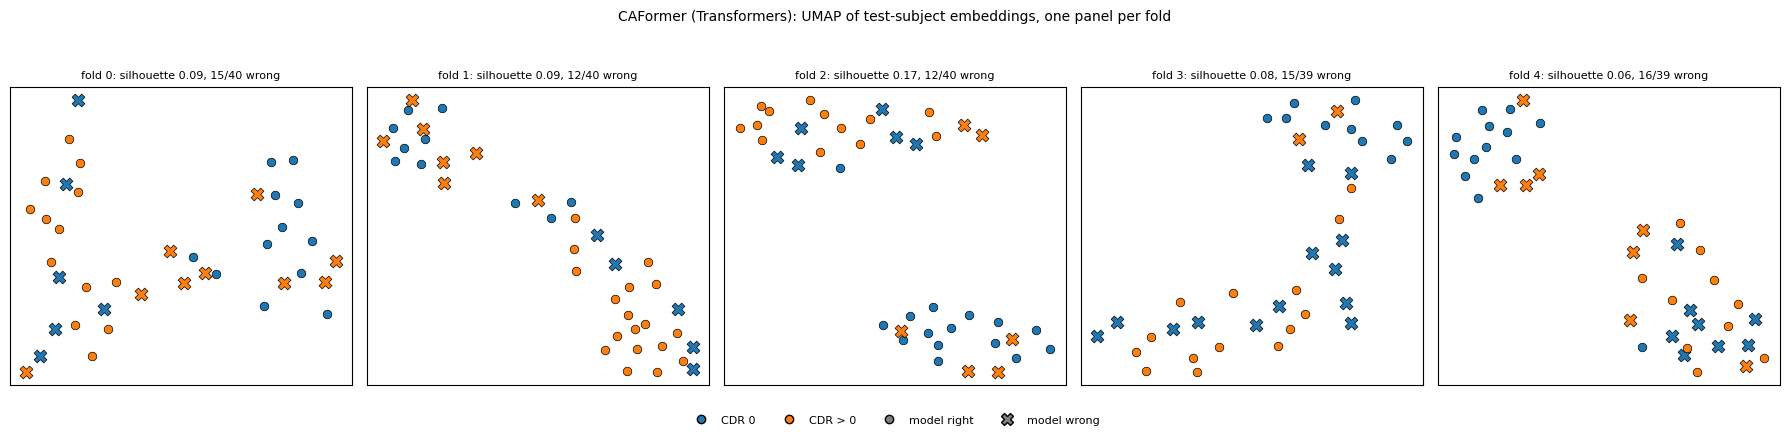

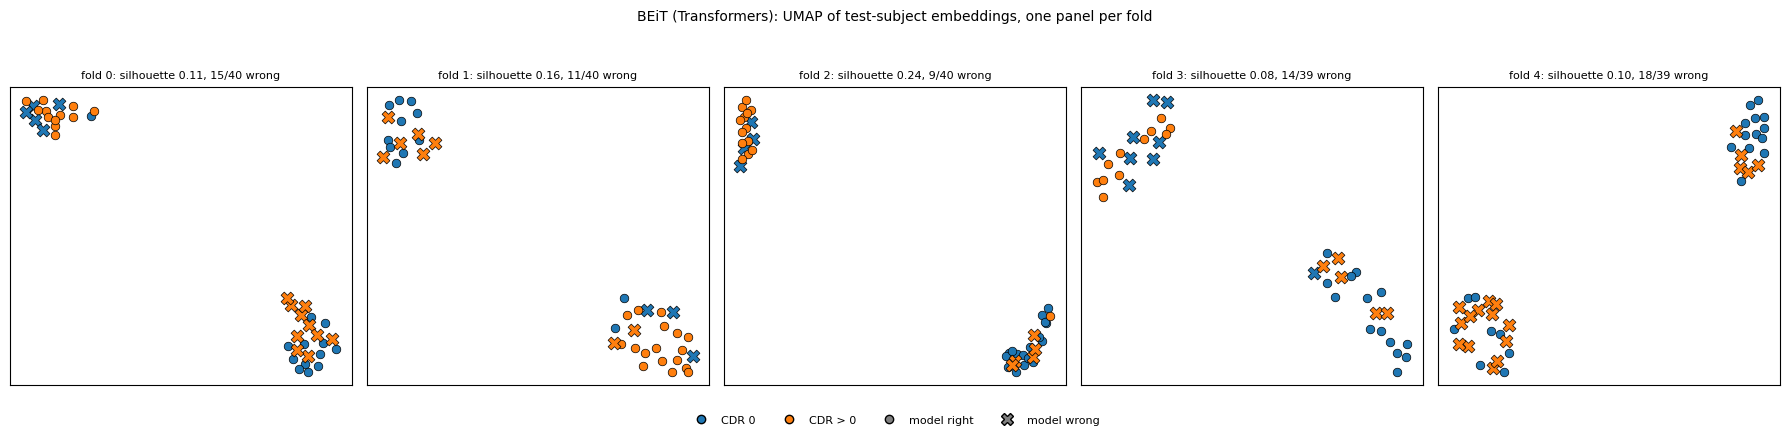

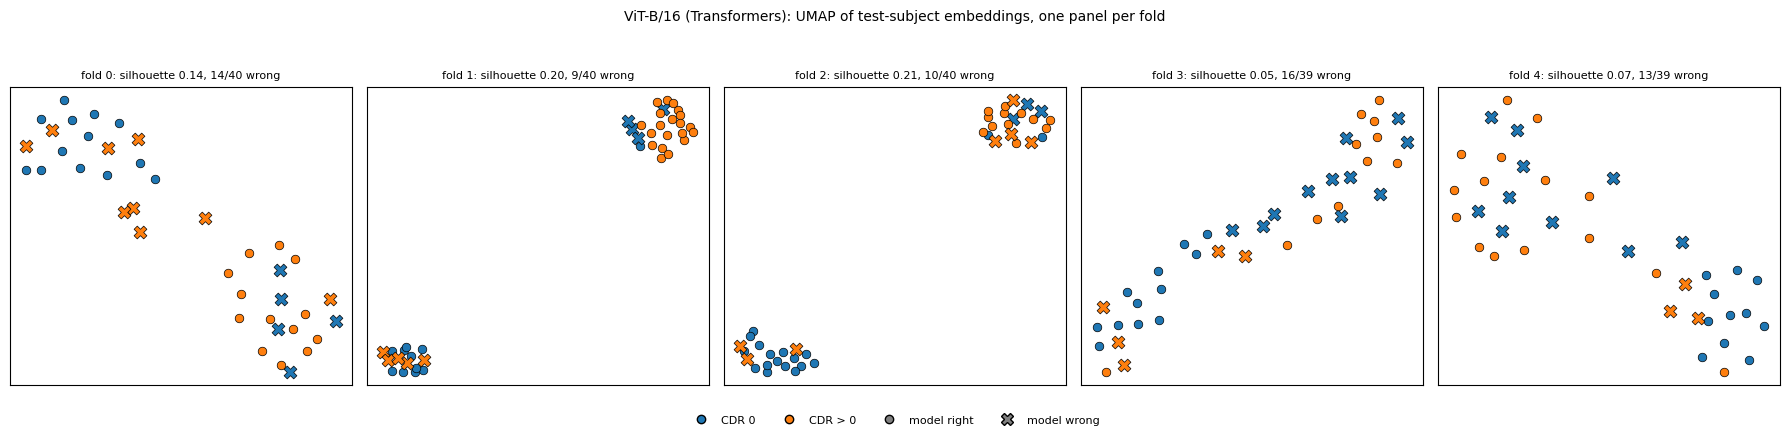

Class separation in the embedding (silhouette, mean ± std over folds):
             silhouette
model                  
CAFormer  0.096 ± 0.044
BEiT      0.138 ± 0.062
ViT-B/16  0.134 ± 0.071


In [15]:
UMAP_TOP = 3                    # how many best models (by mean test AUC) to plot
UMAP_MODELS = None              # or choose by name, for example ["ConvNeXt V2", "Swin"]
UMAP_NEIGHBORS, UMAP_MIN_DIST = 8, 0.3     # small neighbourhood, because each fold has only about 40 test subjects

mean_auc = res.groupby("model").auc.mean().sort_values(ascending=False)
BEST = list(UMAP_MODELS) if UMAP_MODELS else list(mean_auc.index[:UMAP_TOP])
print("Models plotted (mean test AUC):", ", ".join(f"{m} ({mean_auc.get(m, float('nan')):.3f})" for m in BEST))
EMB_FILES = sorted(OUT_DIR.glob(f"{TASK}_*_emb.npz"))

import sys, subprocess
try:
    import umap
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "umap-learn"])
    import umap
from matplotlib.lines import Line2D
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

EMB = {}
for p in EMB_FILES:
    z = np.load(p, allow_pickle=True)
    EMB[(str(z["model"]), int(z["fold"]))] = (z["subject"], z["emb"])
print(f"{len(EMB)} embedding files | models: {sorted({m for m, _ in EMB})}")

sil_rows = []
for m in BEST:
    ks = sorted(k for (mm, k) in EMB if mm == m)
    if not ks:
        print(f"{m}: no embedding files found (they are saved while training, see SAVE_EMBEDDINGS), so it is skipped")
        continue
    fig, axs = plt.subplots(1, len(ks), figsize=(3.6 * len(ks), 4.3), squeeze=False)
    for ax, k in zip(axs[0], ks):
        subj, Xe = EMB[(m, k)]
        d = oof_g[(oof_g.model == m) & (oof_g.fold == k)].set_index("subject").loc[subj]
        y, wrong = d.y.values, hard_pred(d) != d.y.values
        Z = StandardScaler().fit_transform(Xe)
        xy = umap.UMAP(n_neighbors=max(2, min(UMAP_NEIGHBORS, len(subj) - 1)), min_dist=UMAP_MIN_DIST,
                       metric="cosine", random_state=SEED).fit_transform(Z)
        for c in LABELS:
            for flag, mk, sz in ((False, "o", 38), (True, "X", 85)):
                s = (y == c) & (wrong == flag)
                ax.scatter(xy[s, 0], xy[s, 1], c=f"C{c}", marker=mk, s=sz, edgecolors="k", linewidths=0.5)
        sil = silhouette_score(Z, y, metric="cosine") if len(np.unique(y)) >= 2 else np.nan
        sil_rows.append(dict(model=m, fold=k, n_subjects=len(subj), n_wrong=int(wrong.sum()), silhouette=sil))
        ax.set_title(f"fold {k}: silhouette {sil:.2f}, {int(wrong.sum())}/{len(subj)} wrong", fontsize=8)
        ax.set_xticks([]); ax.set_yticks([])
    handles = [Line2D([], [], marker="o", ls="", color=f"C{c}", markeredgecolor="k", label=CLASS_NAMES[c]) for c in LABELS]
    handles += [Line2D([], [], marker="o", ls="", color="grey", markeredgecolor="k", label="model right"),
                Line2D([], [], marker="X", ls="", color="grey", markeredgecolor="k", markersize=9, label="model wrong")]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), fontsize=8, frameon=False)
    fig.suptitle(f"{m} ({GROUP_OF.get(m, '')}): UMAP of test-subject embeddings, one panel per fold", fontsize=10)
    plt.tight_layout(rect=[0, 0.07, 1, 0.94])
    plt.savefig(OUT_DIR / f"{TASK}_umap_{m.replace('/', '-').replace(' ', '_')}.png", dpi=150); plt.show()

if sil_rows:
    sil_df = pd.DataFrame(sil_rows)
    sil_df.to_csv(OUT_DIR / f"{TASK}_umap_silhouette.csv", index=False)
    s = sil_df.groupby("model").silhouette.agg(["mean", "std"]).loc[[m for m in BEST if m in set(sil_df.model)]]
    print("Class separation in the embedding (silhouette, mean \u00b1 std over folds):")
    print(pd.DataFrame({"silhouette": [f"{r['mean']:.3f} \u00b1 {r['std']:.3f}" for _, r in s.iterrows()]}, index=s.index).to_string())

## 7. Paired comparison with the best model (for later use)

The folds are identical for every model, so differences can be paired by fold. With only 5 folds a significance test has little power, so treat this as descriptive. The saved `*_preds.csv` files hold one row per subject, which allows a paired subject-level test (for example DeLong or bootstrap on AUC) when the GCN results are ready.

In [16]:
mean_auc = res.groupby("model").auc.mean().loc[order]
best = mean_auc.idxmax()
pv = res.pivot(index="fold", columns="model", values="auc")
rows = []
for m in order:
    if m == best: continue
    d = (pv[best] - pv[m]).values
    rows.append(dict(best=best, other=m, mean_auc_diff=d.mean(), folds_best_wins=int((d > 0).sum()), n_folds=len(d)))
print(f"Best mean AUC: {best} ({mean_auc[best]:.3f})")
print(pd.DataFrame(rows).round(3).to_string(index=False))
print("\nSaved files:", sorted(p.name for p in OUT_DIR.iterdir() if p.suffix in ('.csv', '.png', '.json'))[:6], "...")

Best mean AUC: CAFormer (0.748)
    best           other  mean_auc_diff  folds_best_wins  n_folds
CAFormer EfficientNet-B0          0.017                3        5
CAFormer        ResNet50          0.019                3        5
CAFormer     DenseNet201          0.015                3        5
CAFormer     MobileNetV2          0.025                5        5
CAFormer        ConvNeXt          0.060                5        5
CAFormer     ConvNeXt V2          0.108                5        5
CAFormer           NFNet          0.038                4        5
CAFormer   InceptionNeXt          0.034                4        5
CAFormer        RepLKNet          0.024                4        5
CAFormer  EfficientNetV2          0.051                5        5
CAFormer        ViT-B/16          0.005                2        5
CAFormer            Swin          0.027                4        5
CAFormer            DeiT          0.006                3        5
CAFormer            BEiT          0.003     

In [17]:
B = 2000
rng = np.random.default_rng(SEED)
oof = pd.concat([pd.read_csv(p) for p in sorted(OUT_DIR.glob(f"{TASK}_*_preds.csv"))])
P = oof.pivot(index="subject", columns="model", values="p1")                 # subjects x models
y = oof.drop_duplicates("subject").set_index("subject").y.loc[P.index].values
models, n = list(P.columns), len(y)

point = np.array([roc_auc_score(y, P[m].values) for m in models])             # pooled out-of-fold AUC
boot = np.empty((B, len(models)))
for b in range(B):                                                           # resample SUBJECTS with replacement
    while True:
        idx = rng.integers(0, n, n)
        if 0 < y[idx].sum() < n: break
    boot[b] = [roc_auc_score(y[idx], P[m].values[idx]) for m in models]

lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
tab = pd.DataFrame({"model": models, "pooled_AUC": point, "CI_low": lo, "CI_high": hi}).sort_values("pooled_AUC", ascending=False)
print(tab.round(3).to_string(index=False))

ref = int(np.argmax(point))                                                  # best pooled model as the reference
rows = []
for j, m in enumerate(models):
    if j == ref: continue
    d = boot[:, ref] - boot[:, j]
    rows.append(dict(reference=models[ref], other=m, diff=point[ref] - point[j],
                     CI_low=np.percentile(d, 2.5), CI_high=np.percentile(d, 97.5),
                     p_two_sided=min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))))
print("\nPaired bootstrap, same resampled subjects for both models:")
print(pd.DataFrame(rows).round(3).to_string(index=False))

          model  pooled_AUC  CI_low  CI_high
           DeiT       0.736   0.663    0.798
    DenseNet201       0.736   0.663    0.802
       ViT-B/16       0.733   0.660    0.799
       CAFormer       0.733   0.662    0.798
           BEiT       0.728   0.656    0.795
    MobileNetV2       0.715   0.639    0.788
  InceptionNeXt       0.714   0.640    0.780
       ResNet50       0.711   0.638    0.780
           Swin       0.711   0.635    0.778
EfficientNet-B0       0.710   0.636    0.779
       RepLKNet       0.701   0.627    0.769
         MaxViT       0.686   0.608    0.761
          NFNet       0.665   0.587    0.735
 EfficientNetV2       0.658   0.581    0.733
       ConvNeXt       0.656   0.578    0.726
    ConvNeXt V2       0.641   0.560    0.713

Paired bootstrap, same resampled subjects for both models:
reference           other  diff  CI_low  CI_high  p_two_sided
     DeiT            BEiT 0.007  -0.038    0.053        0.784
     DeiT        CAFormer 0.003  -0.036    0.040   